# Old34 donor-healthy downsampling expansion (v2)

Experiment: `20260525_060508_stage0_mrd_old34_broad_screen_82db5093`
Output branch: `donor_sensitivity_v2`

This notebook **does not refit** Stage 1 or Stage 2. It reads the overnight CSVs produced by
`run_stage2_old34_donor_downsampling_sensitivity.py`, which copied the frozen D10/D11 method from
`stage2_old34_donor_downsampling_sensitivity.ipynb` (v1: 7 targeted representations).

Use v1 for the method contract (masks, full held-out evaluation, Hungarian factor alignment,
supervised-factor rule). Use this notebook for the **681-representation landscape**.

## What expanded

| Arm | v1 | v2 |
|---|---|---|
| D10 fixed Stage 1 basis | 7 targets, 490 LOPO fits | 640 DR + 41 direct-gene = **681** targets, 47,670 fits |
| D11 pre-DR PCA/FA refit | IFN-α PCA40 and FA40 | **21** PCA/FA representations (19 panel-selected best-DR + the original IFN-α K=40 pair) |

Regularization remains **frozen** at each representation's globally selected pooled-LOPO setting.
FactoSig / Promax are D10-only. There is still **no condition-specific C rescue**.

## Reading order (same claim gate as v1)

1. Confirm the intervention (D10A / D10A2).
2. **Inspect coefficient collapse (D10E) before any AP-loss plot.**
3. Then look at AP/lift and coefficient-vector stability.
4. For D11, treat AP as a Stage 2 readout; treat aligned score/loading/Jaccard as the Stage 1 evidence.
5. Keep the IFN-α PCA40 / FA40 pair as the v1 case study, not as the whole D11 story.

## Claim boundary

Supported as descriptive findings: whether sparse models go to \(\boldsymbol\beta=\mathbf 0\) when donor-healthy
training cells are reduced, and whether PCA/FA axes move after a transductive refit.

**Not** supported: a donor-versus-recipient origin shortcut; FA intrinsically worse than PCA;
DR universally better than direct genes; deployment-ready selection.


In [1]:
from __future__ import annotations

import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

EXPERIMENT_ID = "20260525_060508_stage0_mrd_old34_broad_screen_82db5093"
SUPPORTED_PATIENTS = ["P01", "P02", "P03", "P04", "P06", "P07", "P09"]
DONOR_FRACTIONS = [1.0, 0.5, 0.25, 0.1]
DOWNSAMPLE_SEEDS = [42, 43, 44]
COEF_TOLERANCE = 1e-8
AP_MATERIALITY_GUIDE = 0.02
FACTOR_SIMILARITY_GUIDE = 0.90
TOP_GENE_JACCARD_GUIDE = 0.50
N_CELLS = 60_118
N_DONOR_HEALTHY = 58_499
N_RECIPIENT_HEALTHY = 50
N_MALIGNANT = 1_569
V1_FIXED_TARGET_IDS = [
    "stress_best_dr",
    "stress_direct",
    "p53_best_dr",
    "p53_direct",
    "ifna_pca40",
    "ifna_fa40",
    "ifna_direct",
]
V1_BASIS_TARGET_IDS = ["ifna_pca40", "ifna_fa40"]
METHOD_LABELS = {
    "pca": "PCA",
    "fa": "FA",
    "factosig": "FactoSig",
    "factosig_promax": "FactoSig-Promax",
    "direct_gene": "direct genes",
}
METHOD_ORDER = ["pca", "fa", "factosig", "factosig_promax", "direct_gene"]
PENALTY_ORDER = ["l1", "elasticnet", "l2"]
FAMILY_ORDER = ["dr", "direct_gene"]
FRACTION_ORDER = [0.5, 0.25, 0.1]


def find_repo_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "sc_classification").exists():
            return candidate
    fallback = Path("/home/minhang/mds_project/sc_classification")
    if fallback.exists():
        return fallback
    raise FileNotFoundError("Could not locate sc_classification repository root")


REPO_ROOT = find_repo_root()
EXP_DIR = REPO_ROOT / "experiments" / EXPERIMENT_ID
DIAGNOSTIC_DIR = EXP_DIR / "analysis" / "scorecards" / "stage2_diagnostic"
TABLE_DIR = DIAGNOSTIC_DIR / "donor_sensitivity_v2"
V1_TABLE_DIR = DIAGNOSTIC_DIR / "donor_sensitivity_v1"
FIGURE_DIR = EXP_DIR / "analysis" / "figures" / "stage2_diagnostic" / "donor_sensitivity_v2"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
ROLE_PALETTE = {
    "Other factor": sns.color_palette()[0],
    "Nonzero supervised factor": sns.color_palette()[1],
}
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_rows", 80)

GENERATED_TABLES: list[Path] = []
GENERATED_FIGURES: list[Path] = []


def write_csv(frame: pd.DataFrame, filename: str) -> Path:
    path = TABLE_DIR / filename
    frame.to_csv(path, index=False)
    GENERATED_TABLES.append(path)
    return path


def save_figure(fig: plt.Figure, stem: str) -> Path:
    png = FIGURE_DIR / f"{stem}.png"
    pdf = png.with_suffix(".pdf")
    fig.savefig(png, dpi=220, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    GENERATED_FIGURES.extend([png, pdf])
    print(png)
    return png


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def method_label(method: str) -> str:
    return METHOD_LABELS.get(str(method), str(method))


def annotate_groups(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    if "stage1_method" in out.columns:
        out["method_label"] = out["stage1_method"].map(method_label)
    if "representation_family" in out.columns:
        out["family_label"] = np.where(out["representation_family"].eq("direct_gene"), "direct gene", "DR")
    if "target_id" in out.columns:
        out["is_v1_overlap"] = out["target_id"].isin(V1_FIXED_TARGET_IDS)
    if "penalty" in out.columns:
        out["penalty"] = pd.Categorical(out["penalty"], PENALTY_ORDER, ordered=True)
    return out


required = {
    "run_state": TABLE_DIR / "RUN_STATE.json",
    "v1_qa": TABLE_DIR / "v1_qa_report.json",
    "manifest": TABLE_DIR / "target_manifest.csv",
    "d11_manifest": TABLE_DIR / "basis_refit_target_manifest.csv",
    "d10_metrics": TABLE_DIR / "fixed_basis_patient_metrics.csv",
    "d10_collapse": TABLE_DIR / "fixed_basis_collapse_summary.csv",
    "d10_stability": TABLE_DIR / "fixed_basis_coefficient_stability.csv",
    "d10_supervised": TABLE_DIR / "fixed_basis_full_donor_supervised_features.csv",
    "d10_counts": TABLE_DIR / "fixed_basis_donor_downsampling_retained_counts.csv",
    "d11_metrics": TABLE_DIR / "basis_refit_patient_metrics.csv",
    "d11_stability": TABLE_DIR / "basis_refit_factor_stability.csv",
    "d11_performance": TABLE_DIR / "basis_refit_performance_summary.csv",
    "v1_d10": V1_TABLE_DIR / "fixed_basis_donor_downsampling_patient_metrics.csv",
    "v1_d11": V1_TABLE_DIR / "ifna_basis_refit_patient_metrics.csv",
    "v1_stratum": V1_TABLE_DIR / "donor_sensitivity_stratum_realized_fraction_25pct_seed42.csv",
    "v1_patients": V1_TABLE_DIR / "donor_sensitivity_patient_composition.csv",
    "d9": DIAGNOSTIC_DIR / "meeting_followup_v1" / "old34_direct_gene_vs_best_dr_summary.csv",
}
missing = [f"{name}: {path}" for name, path in required.items() if not path.exists()]
if missing:
    raise FileNotFoundError("Missing v2/v1 inputs:\n" + "\n".join(missing))

run_state = json.loads(required["run_state"].read_text())
v1_qa = json.loads(required["v1_qa"].read_text())
manifest = annotate_groups(pd.read_csv(required["manifest"]))
d11_manifest = annotate_groups(pd.read_csv(required["d11_manifest"]))
d10 = annotate_groups(pd.read_csv(required["d10_metrics"]))
d10_collapse = annotate_groups(pd.read_csv(required["d10_collapse"]).merge(
    manifest[["target_id", "stage1_method", "representation_family", "penalty", "short_panel_label", "stage0_panel_id"]],
    on="target_id",
    how="left",
    validate="many_to_one",
))
d10_stability = annotate_groups(pd.read_csv(required["d10_stability"]))
d10_supervised = pd.read_csv(required["d10_supervised"])
d10_counts = pd.read_csv(required["d10_counts"])
d11 = annotate_groups(pd.read_csv(required["d11_metrics"]))
d11_stability = annotate_groups(pd.read_csv(required["d11_stability"]))
d11_performance = pd.read_csv(required["d11_performance"])
v1_d10 = pd.read_csv(required["v1_d10"])
v1_d11 = pd.read_csv(required["v1_d11"])
v1_stratum = pd.read_csv(required["v1_stratum"])
patient_composition = pd.read_csv(required["v1_patients"])
d9 = pd.read_csv(required["d9"])

d10["zero_coefficient_solution"] = d10["active_coefficient_count"].eq(0)
d11["zero_coefficient_solution"] = d11["active_coefficient_count"].eq(0)
d10_stability["had_full_donor_probe"] = d10_stability["reference_active_feature_count"].gt(0)

print("Repository:", REPO_ROOT)
print("v2 tables:", TABLE_DIR)
print("RUN_STATE:", run_state.get("status"))
print("D10 targets/rows:", d10["target_id"].nunique(), len(d10))
print("D11 targets/rows:", d11["target_id"].nunique(), len(d11))


Repository: /home/minhang/mds_project/sc_classification
v2 tables: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/donor_sensitivity_v2
RUN_STATE: complete
D10 targets/rows: 681 47670
D11 targets/rows: 21 1470


## 1. Accounting, v1 QA, and the 80 empty supervised files

The overnight job finished all D10 and D11 targets. Merge originally crashed on 80 empty
`supervised.csv` files: those representations already had \(\boldsymbol\beta=\mathbf 0\) at full donor, so there
were no nonzero full-donor coefficients to store. Metrics, collapse, and coefficient-stability
rows still exist for them.


In [2]:
assert run_state.get("status") == "complete", run_state
assert run_state["fixed_basis"]["n_completed"] == 681
assert run_state["basis_refit"]["n_completed"] == 21
assert run_state["fixed_basis"]["n_failed"] == 0
assert run_state["basis_refit"]["n_failed"] == 0
assert len(d10) == 681 * 10 * 7
assert len(d11) == 21 * 10 * 7
assert d10.loc[d10["donor_fraction"].eq(1.0), "delta_heldout_auprc_vs_full_donor"].abs().max() < 1e-12

qa_fixed = next(report for report in v1_qa["reports"] if report["label"] == "fixed_basis")
qa_basis = next(report for report in v1_qa["reports"] if report["label"] == "basis_refit")
print("v1 QA D10:", qa_fixed)
print("v1 QA D11:", qa_basis)
assert qa_fixed["passed"] and qa_basis["passed"]
assert qa_fixed["n_compared_rows"] == 490
assert qa_basis["n_compared_rows"] == 140
assert qa_fixed["max_abs_ap_error"] < 1e-3
assert qa_fixed["n_collapse_mismatches"] == 0

full_collapse = d10_collapse.loc[d10_collapse["donor_fraction"].eq(1.0)].copy()
n_full_zero_targets = int(full_collapse["zero_solution_fraction"].eq(1.0).sum())
n_full_any_zero = int(full_collapse["n_zero_fits"].gt(0).sum())
n_supervised_targets = d10_supervised["target_id"].nunique()
print(f"Full-donor 100% collapse targets: {n_full_zero_targets}")
print(f"Full-donor any all-zero LOPO fold: {n_full_any_zero}")
print(f"Targets with stored nonzero supervised features: {n_supervised_targets} (681 - {n_full_zero_targets} = {681 - n_full_zero_targets})")
assert n_supervised_targets == 681 - n_full_zero_targets

accounting = pd.DataFrame(
    [
        {"item": "D10 targets", "value": int(manifest["target_id"].nunique())},
        {"item": "D10 DR / direct-gene", "value": f"{int(manifest.representation_family.eq('dr').sum())} / {int(manifest.representation_family.eq('direct_gene').sum())}"},
        {"item": "D10 Stage 2 fits", "value": len(d10)},
        {"item": "D11 PCA/FA targets", "value": int(d11_manifest['target_id'].nunique())},
        {"item": "D11 Stage 2 fits", "value": len(d11)},
        {"item": "v1 QA max |ΔAP| (D10)", "value": f"{qa_fixed['max_abs_ap_error']:.2e}"},
        {"item": "Full-donor all-zero targets (empty supervised.csv)", "value": n_full_zero_targets},
    ]
)
display(accounting)
display(
    manifest.groupby(["representation_family", "stage1_method", "penalty"], observed=True)
    .size()
    .rename("n_targets")
    .reset_index()
    .pivot_table(index=["representation_family", "stage1_method"], columns="penalty", values="n_targets", fill_value=0)
    .astype(int)
)
print("D11 inclusion reasons")
display(d11_manifest["d11_inclusion_reason"].value_counts(dropna=False).rename("n").to_frame())
display(patient_composition)
print("Seven supported patients for lift/AP summaries:", SUPPORTED_PATIENTS)


v1 QA D10: {'label': 'fixed_basis', 'n_compared_rows': 490, 'max_abs_ap_error': 0.0008160565066185899, 'n_collapse_mismatches': 0, 'passed': True}
v1 QA D11: {'label': 'basis_refit', 'n_compared_rows': 140, 'max_abs_ap_error': 2.613082302460601e-05, 'n_collapse_mismatches': 0, 'passed': True}
Full-donor 100% collapse targets: 80
Full-donor any all-zero LOPO fold: 123
Targets with stored nonzero supervised features: 601 (681 - 80 = 601)


,item,value
0,D10 targets,681
1,D10 DR / direct-gene,640 / 41
2,D10 Stage 2 fits,47670
3,D11 PCA/FA targets,21
4,D11 Stage 2 fits,1470
5,v1 QA max |ΔAP| (D10),8.16e-04
6,Full-donor all-zero targets (empty supervised.csv),80


/tmp/ipykernel_2402917/2169609561.py:46: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(index=["representation_family", "stage1_method"], columns="penalty", values="n_targets", fill_value=0)


penalty                                l1  elasticnet  l2
representation_family stage1_method                      
direct_gene           direct_gene       7          11  23
dr                    fa               28          60  72
                      factosig         22          59  79
                      factosig_promax  37          63  60
                      pca              19          63  78

D11 inclusion reasons


,n
d11_inclusion_reason,
best_dr_pca_fa,19
ifna_case_study,2


,patient,n_cells,n_malignant,n_donor_healthy,n_recipient_healthy
0,P01,11860,45,11815,0
1,P02,1462,211,1234,17
2,P03,2327,758,1568,1
3,P04,1128,102,1012,14
4,P05,4359,8,4341,10
5,P06,3259,44,3214,1
6,P07,2185,22,2163,0
7,P08,1411,0,1411,0
8,P09,17126,375,16745,6
9,P10,2715,0,2715,0


Seven supported patients for lift/AP summaries: ['P01', 'P02', 'P03', 'P04', 'P06', 'P07', 'P09']


## 2. D10A / D10A2 — the intervention is unchanged

Masks were precomputed once and reused for every target. D10A is the v2 retained-count table.
D10A2 reuses the v1 stratum QC CSV: the 25% seed-42 mask is the same patient × predicted-cell-type
rule, including the five-cell floor.


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10A_retained_donor_healthy_counts.png


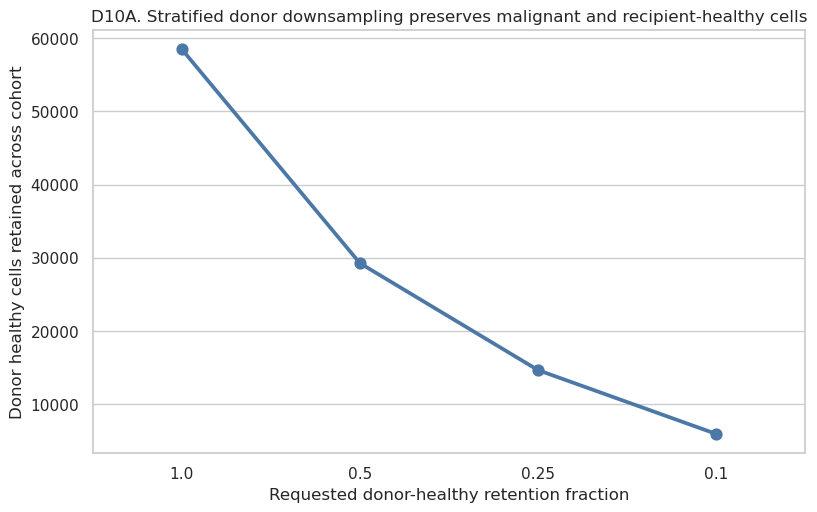

,donor_fraction,downsample_seed,donor_healthy_before,donor_healthy_retained,recipient_healthy_retained,malignant_retained
0,0.10,42,58499,5950,50,1569
1,0.10,43,58499,5950,50,1569
2,0.10,44,58499,5950,50,1569
3,0.25,42,58499,14665,50,1569
4,0.25,43,58499,14665,50,1569
5,0.25,44,58499,14665,50,1569
6,0.50,42,58499,29268,50,1569
7,0.50,43,58499,29268,50,1569
8,0.50,44,58499,29268,50,1569
9,1.00,42,58499,58499,50,1569


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10A2_stratum_realized_retention_25pct.png


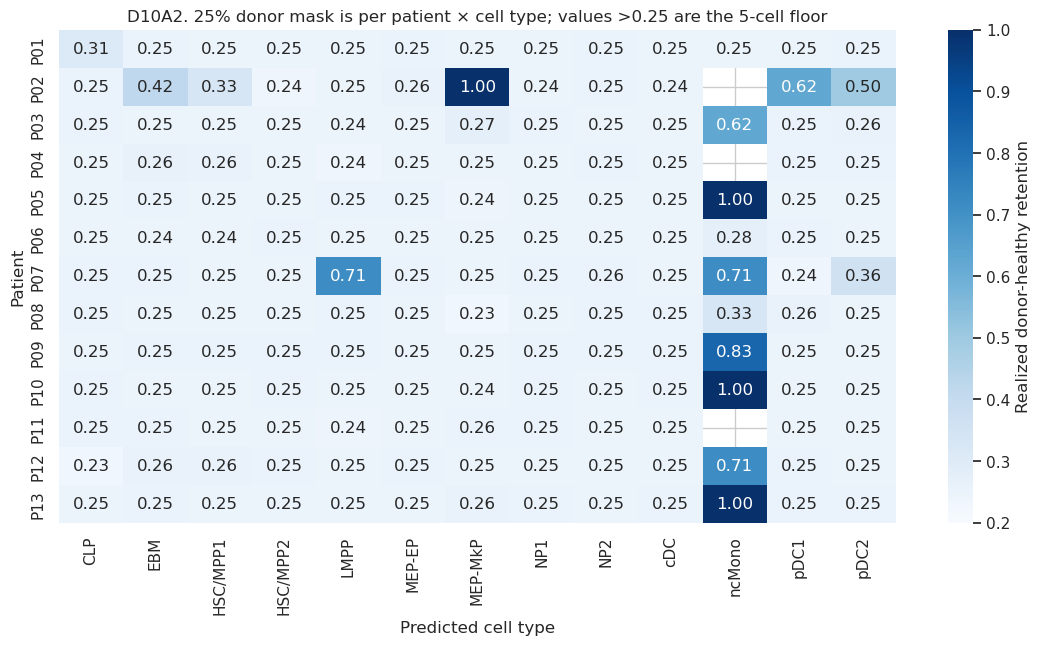

Strata at 25% seed 42: 166 ; floor-bound (realized > 0.26): 19


In [3]:
retained_summary = (
    d10_counts.groupby(["donor_fraction", "downsample_seed"], as_index=False)
    .agg(
        donor_healthy_before=("donor_healthy_before", "sum"),
        donor_healthy_retained=("donor_healthy_retained", "sum"),
        recipient_healthy_retained=("recipient_healthy_retained", "sum"),
        malignant_retained=("malignant_retained", "sum"),
    )
)
assert retained_summary["malignant_retained"].eq(N_MALIGNANT).all()
assert retained_summary["recipient_healthy_retained"].eq(N_RECIPIENT_HEALTHY).all()
assert retained_summary.loc[retained_summary["donor_fraction"].eq(1.0), "donor_healthy_retained"].eq(N_DONOR_HEALTHY).all()

fig, ax = plt.subplots(figsize=(9.2, 5.5))
sns.pointplot(
    data=retained_summary,
    x="donor_fraction",
    y="donor_healthy_retained",
    order=DONOR_FRACTIONS,
    errorbar="sd",
    color="#4C78A8",
    markers="o",
    linestyles="-",
    ax=ax,
)
ax.set_xlabel("Requested donor-healthy retention fraction")
ax.set_ylabel("Donor healthy cells retained across cohort")
ax.set_title("D10A. Stratified donor downsampling preserves malignant and recipient-healthy cells")
save_figure(fig, "D10A_retained_donor_healthy_counts")
plt.show()
display(retained_summary.sort_values(["donor_fraction", "downsample_seed"]))

stratum_matrix = v1_stratum.pivot(index="patient", columns="predicted.annotation", values="realized_fraction")
fig, ax = plt.subplots(figsize=(13.5, 6.4))
sns.heatmap(
    stratum_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0.2,
    vmax=1.0,
    cbar_kws={"label": "Realized donor-healthy retention"},
    ax=ax,
)
ax.set_xlabel("Predicted cell type")
ax.set_ylabel("Patient")
ax.set_title("D10A2. 25% donor mask is per patient × cell type; values >0.25 are the 5-cell floor")
save_figure(fig, "D10A2_stratum_realized_retention_25pct")
plt.show()
print(
    "Strata at 25% seed 42:",
    len(v1_stratum),
    "; floor-bound (realized > 0.26):",
    int((v1_stratum["realized_fraction"] > 0.26).sum()),
)


## 3. D10E first — collapse is a fixed-\(C\) pathology, not a donor-identity test

v1's main correction still holds at 681 targets: if a sparse model goes to \(\boldsymbol\beta=\mathbf 0\), then
held-out AP equals prevalence and \(\Delta\)AP equals minus that fold's full-donor lift. Read D10E
**before** D10B.

At this scale a 681-row heatmap is unreadable, so the v1 per-target heatmap is kept only for the
original 7 targets. The landscape views are method × fraction, penalty × fraction, and the
distribution of per-target collapse rates.


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10E_collapse_by_method.png


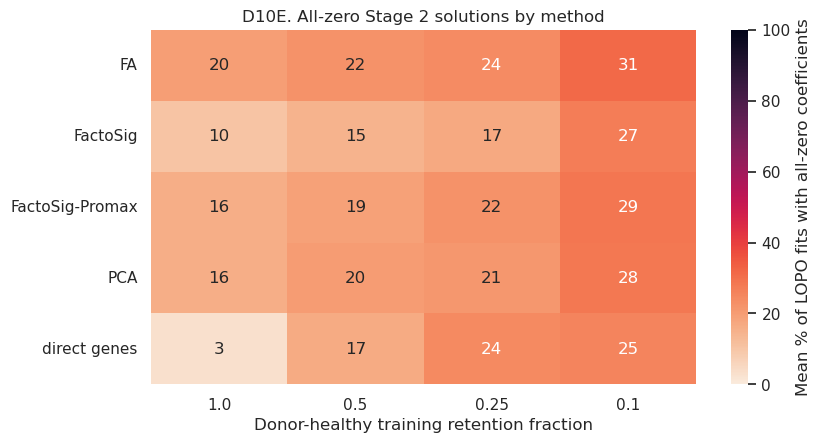

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10E2_collapse_by_penalty.png


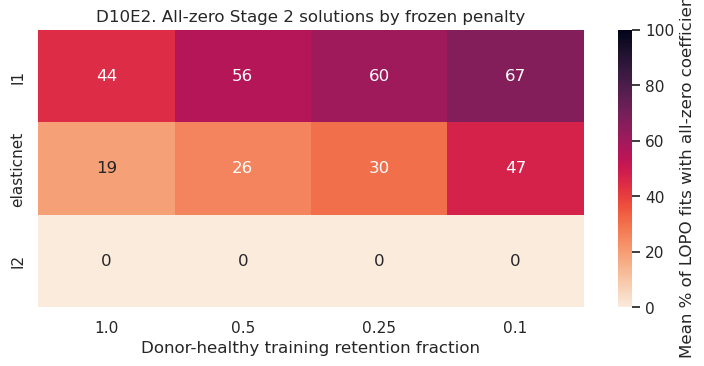

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10E3_n_targets_full_collapse.png


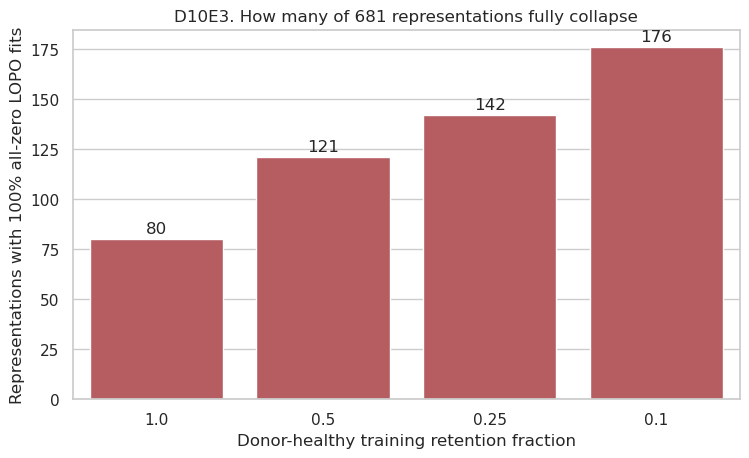

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10E4_collapse_distribution_25pct.png


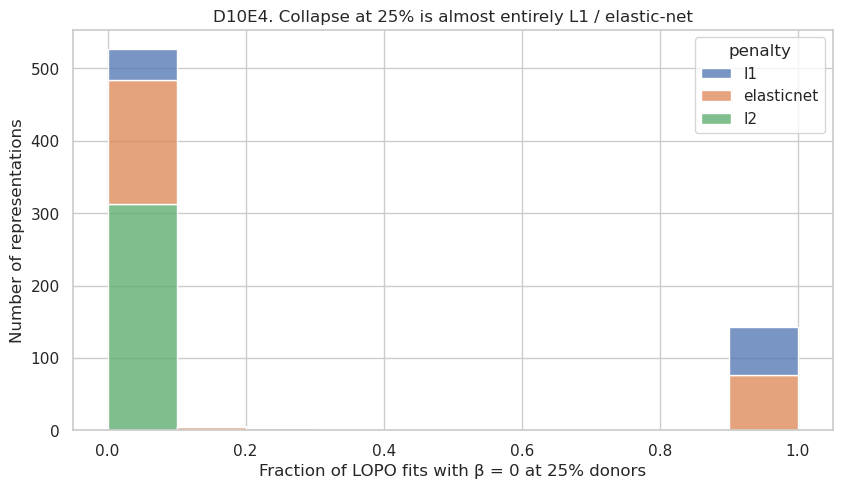

L2 never collapses (fixed-C pathology is sparsity-path specific):


donor_fraction,1.00,0.50,0.25,0.10
penalty,,,,
l1,0.443742,0.557522,0.604298,0.666667
elasticnet,0.194754,0.257254,0.303013,0.469308
l2,0.000000,0.000000,0.000000,0.000000


,donor_fraction,n_targets,n_allzero_targets,mean_collapse,n_any_zero
0,0.10,681,176,0.287043,248
1,0.25,681,142,0.214181,155
2,0.50,681,121,0.189218,138
3,1.00,681,80,0.146843,123


stage1_method,pca,fa,factosig,factosig_promax,direct_gene
penalty,,,,,
l1,0.842105,0.821429,0.409091,0.386100,0.857143
elasticnet,0.289494,0.255556,0.312349,0.342404,0.363636
l2,0.000000,0.000000,0.000000,0.000000,0.000000


In [4]:
def collapse_heatmap(frame: pd.DataFrame, index: str, title: str, stem: str, figsize=(8.8, 4.6)):
    matrix = (
        frame.groupby([index, "donor_fraction"], observed=True)["zero_solution_fraction"]
        .mean()
        .unstack()
        .reindex(columns=DONOR_FRACTIONS)
    )
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        100 * matrix,
        annot=True,
        fmt=".0f",
        cmap="rocket_r",
        vmin=0,
        vmax=100,
        cbar_kws={"label": "Mean % of LOPO fits with all-zero coefficients"},
        ax=ax,
    )
    ax.set_xlabel("Donor-healthy training retention fraction")
    ax.set_ylabel("")
    ax.set_title(title)
    save_figure(fig, stem)
    plt.show()
    return matrix


method_collapse = collapse_heatmap(
    d10_collapse.assign(method_label=d10_collapse["stage1_method"].map(method_label)),
    "method_label",
    "D10E. All-zero Stage 2 solutions by method",
    "D10E_collapse_by_method",
)
penalty_collapse = collapse_heatmap(
    d10_collapse,
    "penalty",
    "D10E2. All-zero Stage 2 solutions by frozen penalty",
    "D10E2_collapse_by_penalty",
    figsize=(8.8, 3.6),
)

n_allzero = (
    d10_collapse.groupby("donor_fraction", as_index=False)
    .agg(
        n_targets=("target_id", "nunique"),
        n_allzero_targets=("zero_solution_fraction", lambda s: int(s.eq(1.0).sum())),
        mean_collapse=("zero_solution_fraction", "mean"),
        n_any_zero=("n_zero_fits", lambda s: int(s.gt(0).sum())),
    )
)
n_allzero_path = write_csv(n_allzero, "fixed_basis_collapse_target_counts.csv")

fig, ax = plt.subplots(figsize=(8.6, 4.8))
sns.barplot(data=n_allzero, x="donor_fraction", y="n_allzero_targets", order=DONOR_FRACTIONS, color="#C44E52", ax=ax)
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("Representations with 100% all-zero LOPO fits")
ax.set_title("D10E3. How many of 681 representations fully collapse")
for x, row in n_allzero.set_index("donor_fraction").loc[DONOR_FRACTIONS].iterrows():
    ax.text(DONOR_FRACTIONS.index(x), row["n_allzero_targets"] + 3, f"{int(row['n_allzero_targets'])}", ha="center")
save_figure(fig, "D10E3_n_targets_full_collapse")
plt.show()

collapse_25 = d10_collapse.loc[d10_collapse["donor_fraction"].eq(0.25)].copy()
fig, ax = plt.subplots(figsize=(9.8, 5.2))
sns.histplot(
    data=collapse_25,
    x="zero_solution_fraction",
    hue="penalty",
    hue_order=PENALTY_ORDER,
    multiple="stack",
    bins=np.linspace(0, 1, 11),
    ax=ax,
)
ax.set_xlabel("Fraction of LOPO fits with β = 0 at 25% donors")
ax.set_ylabel("Number of representations")
ax.set_title("D10E4. Collapse at 25% is almost entirely L1 / elastic-net")
save_figure(fig, "D10E4_collapse_distribution_25pct")
plt.show()

print("L2 never collapses (fixed-C pathology is sparsity-path specific):")
display(d10_collapse.groupby(["penalty", "donor_fraction"], observed=True)["zero_solution_fraction"].mean().unstack().reindex(index=PENALTY_ORDER, columns=DONOR_FRACTIONS))
display(n_allzero)
display(
    collapse_25.groupby(["penalty", "stage1_method"], observed=True)["zero_solution_fraction"]
    .mean()
    .unstack()
    .reindex(index=PENALTY_ORDER, columns=METHOD_ORDER)
)


## 4. D10 performance and coefficient stability after collapse is visible

D10B–D10D in v1 used one hue per target. That does not scale. Here:

- **v1 continuity** replots the original 7 targets from the v2 tables (should match v1).
- **Landscape** aggregates 681 representations by method, penalty, and family.
- **D10I** is the new diagnostic that v1 could not draw: per-target collapse rate versus mean \(\Delta\)AP.
- **D10J** pairs each panel's D9 best-DR representation with its direct-gene baseline at 25% donors.

Coefficient cosine/Jaccard is shown only for folds that had a nonzero full-donor probe. All-zero
\(\to\) all-zero is a collapse event, not factor-use stability.


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10B_v1_overlap_ap_change.png


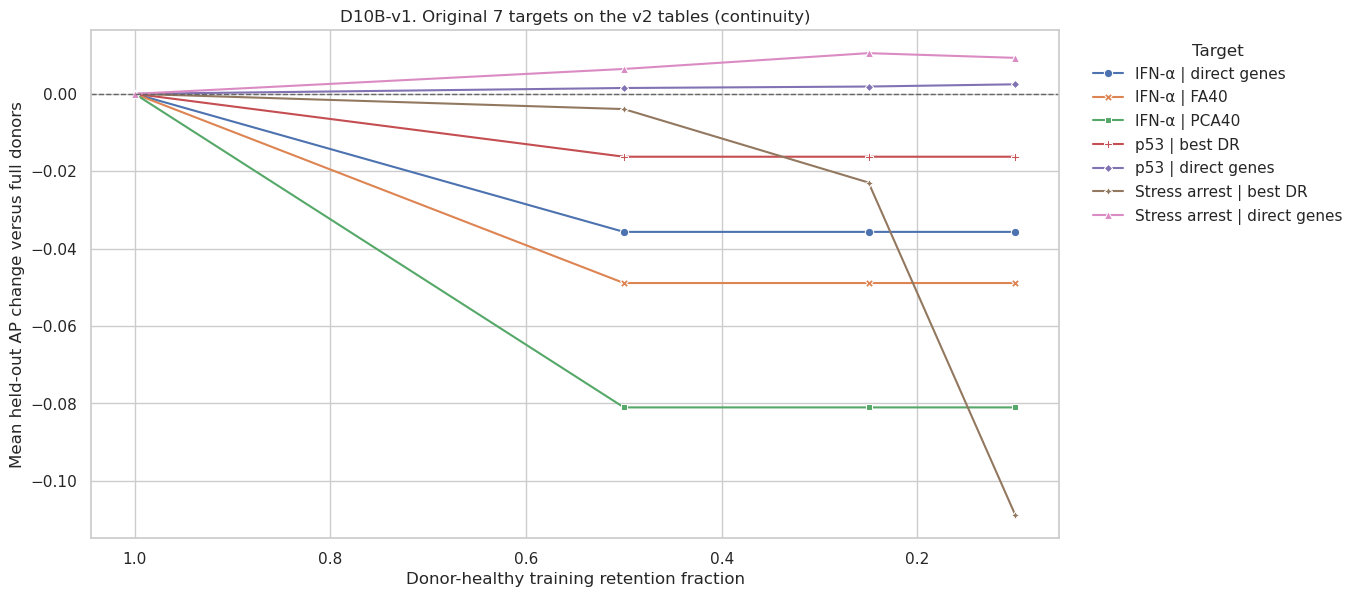

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10E_v1_overlap_collapse.png


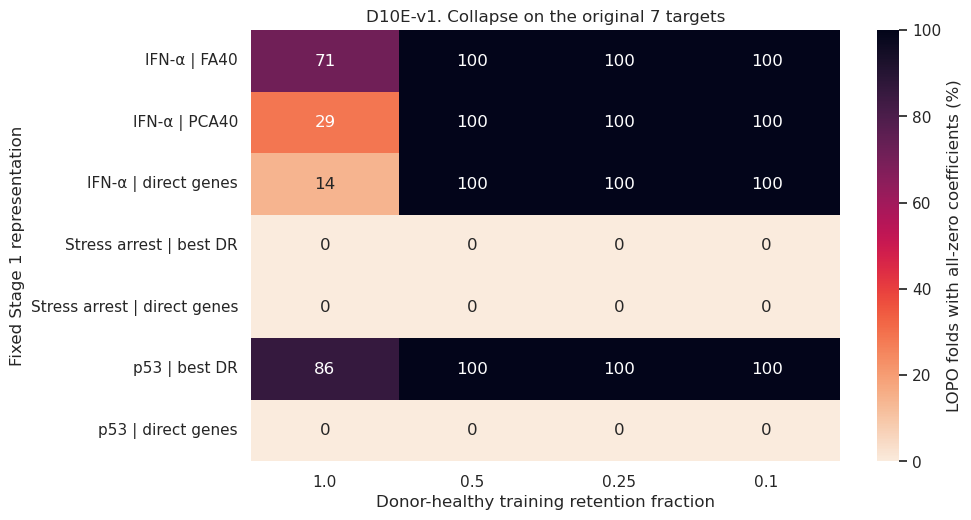

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10C_v1_overlap_patient_ap_change_25pct.png


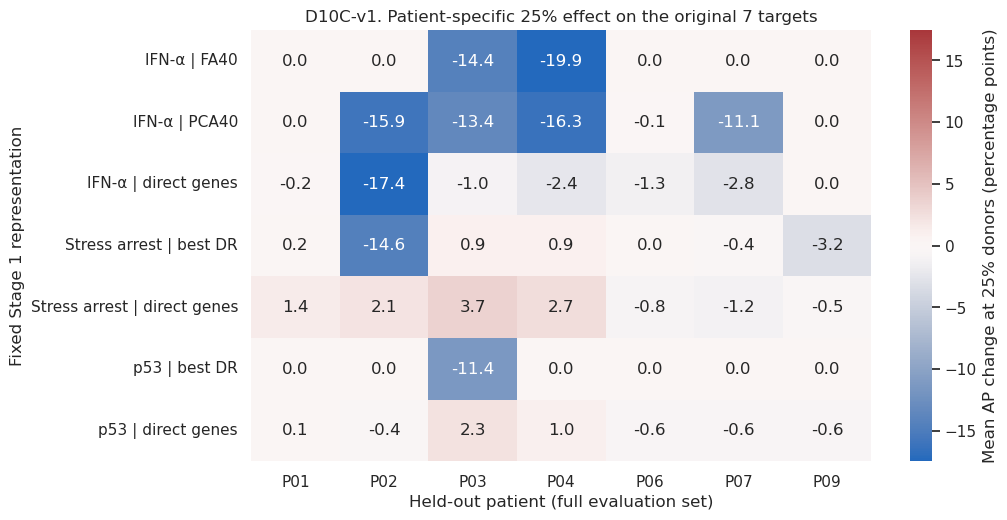

,target_label,mean_delta_ap,worst_delta_ap,collapse
1,IFN-α | direct genes,-0.035690,-0.173631,1.0
5,IFN-α | FA40,-0.048910,-0.198709,1.0
9,IFN-α | PCA40,-0.081062,-0.162672,1.0
13,p53 | best DR,-0.016261,-0.113826,1.0
17,p53 | direct genes,0.001882,-0.009726,0.0
2717,Stress arrest | best DR,-0.022939,-0.151696,0.0
2721,Stress arrest | direct genes,0.010513,-0.014758,0.0


In [5]:
d10_summary = (
    d10.groupby(["target_id", "donor_fraction"], as_index=False)
    .agg(
        mean_delta_ap=("delta_heldout_auprc_vs_full_donor", "mean"),
        median_delta_ap=("delta_heldout_auprc_vs_full_donor", "median"),
        worst_delta_ap=("delta_heldout_auprc_vs_full_donor", "min"),
        mean_lift=("heldout_lift", "mean"),
        mean_ap=("heldout_auprc", "mean"),
        mean_active=("active_coefficient_count", "mean"),
        collapse=("zero_coefficient_solution", "mean"),
    )
    .merge(
        d10.drop_duplicates("target_id")[
            [
                "target_id",
                "target_label",
                "stage0_panel_id",
                "short_panel_label",
                "representation_id",
                "representation_family",
                "stage1_method",
                "method_label",
                "effective_k",
                "n_features",
                "penalty",
                "is_v1_overlap",
                "family_label",
            ]
        ],
        on="target_id",
        how="left",
        validate="many_to_one",
    )
)
d10_summary_path = write_csv(d10_summary, "fixed_basis_donor_downsampling_summary.csv")
v1_summary = d10_summary.loc[d10_summary["is_v1_overlap"]].copy()

fig, ax = plt.subplots(figsize=(12.5, 6.6))
sns.lineplot(
    data=v1_summary,
    x="donor_fraction",
    y="mean_delta_ap",
    hue="target_label",
    style="target_label",
    markers=True,
    dashes=False,
    ax=ax,
)
ax.axhline(0, color="0.4", lw=1, ls="--")
ax.invert_xaxis()
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("Mean held-out AP change versus full donors")
ax.set_title("D10B-v1. Original 7 targets on the v2 tables (continuity)")
ax.legend(title="Target", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure(fig, "D10B_v1_overlap_ap_change")
plt.show()

v1_collapse = d10_collapse.loc[d10_collapse["target_id"].isin(V1_FIXED_TARGET_IDS)]
v1_collapse_matrix = v1_collapse.pivot(index="target_label", columns="donor_fraction", values="zero_solution_fraction").reindex(columns=DONOR_FRACTIONS)
fig, ax = plt.subplots(figsize=(9.5, 5.6))
sns.heatmap(100 * v1_collapse_matrix, annot=True, fmt=".0f", cmap="rocket_r", vmin=0, vmax=100,
            cbar_kws={"label": "LOPO folds with all-zero coefficients (%)"}, ax=ax)
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("Fixed Stage 1 representation")
ax.set_title("D10E-v1. Collapse on the original 7 targets")
save_figure(fig, "D10E_v1_overlap_collapse")
plt.show()

v1_25 = (
    d10.loc[d10["is_v1_overlap"] & d10["donor_fraction"].eq(0.25)]
    .groupby(["target_label", "heldout_patient"], as_index=False)
    .agg(mean_delta_ap=("delta_heldout_auprc_vs_full_donor", "mean"))
)
v1_25_matrix = v1_25.pivot(index="target_label", columns="heldout_patient", values="mean_delta_ap").reindex(columns=SUPPORTED_PATIENTS)
vmax = max(float(np.nanpercentile(np.abs(v1_25_matrix.to_numpy()), 98)), 0.005)
fig, ax = plt.subplots(figsize=(10.0, 5.6))
sns.heatmap(100 * v1_25_matrix, annot=True, fmt=".1f", cmap="vlag", center=0, vmin=-100 * vmax, vmax=100 * vmax,
            cbar_kws={"label": "Mean AP change at 25% donors (percentage points)"}, ax=ax)
ax.set_xlabel("Held-out patient (full evaluation set)")
ax.set_ylabel("Fixed Stage 1 representation")
ax.set_title("D10C-v1. Patient-specific 25% effect on the original 7 targets")
save_figure(fig, "D10C_v1_overlap_patient_ap_change_25pct")
plt.show()

display(v1_summary.loc[v1_summary["donor_fraction"].eq(0.25), ["target_label", "mean_delta_ap", "worst_delta_ap", "collapse"]])


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10B_landscape_ap_change.png


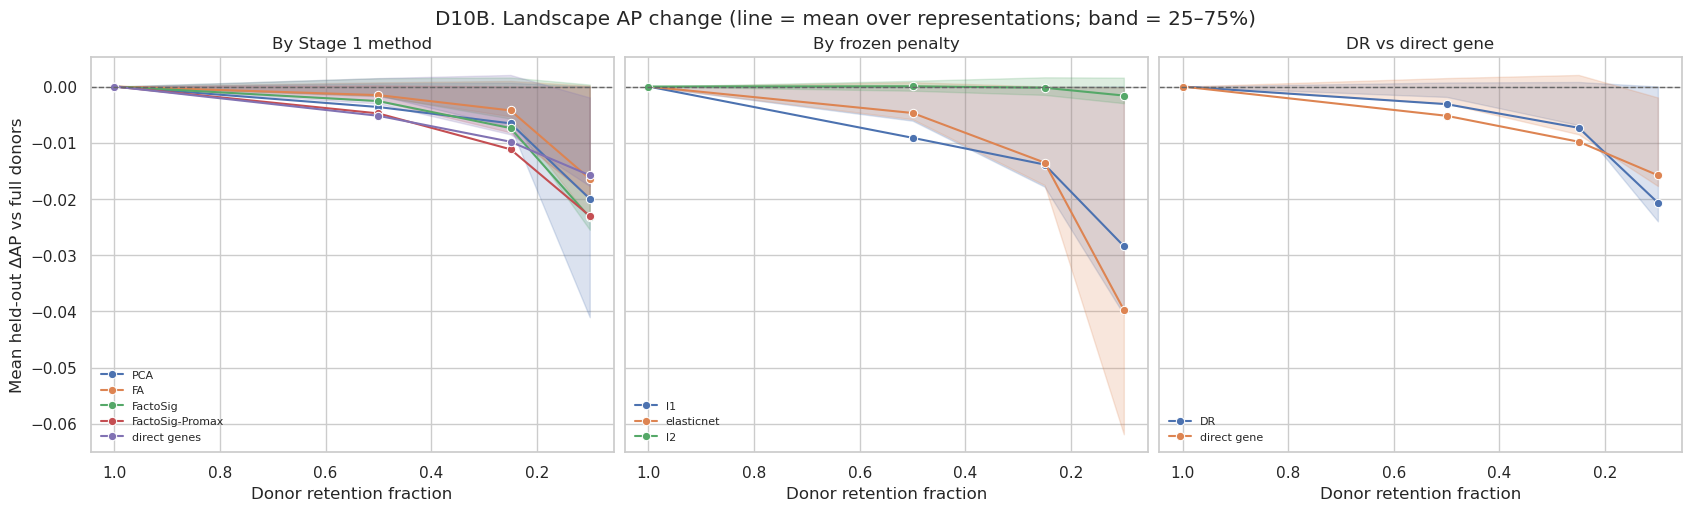

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10C_method_patient_ap_change_25pct.png


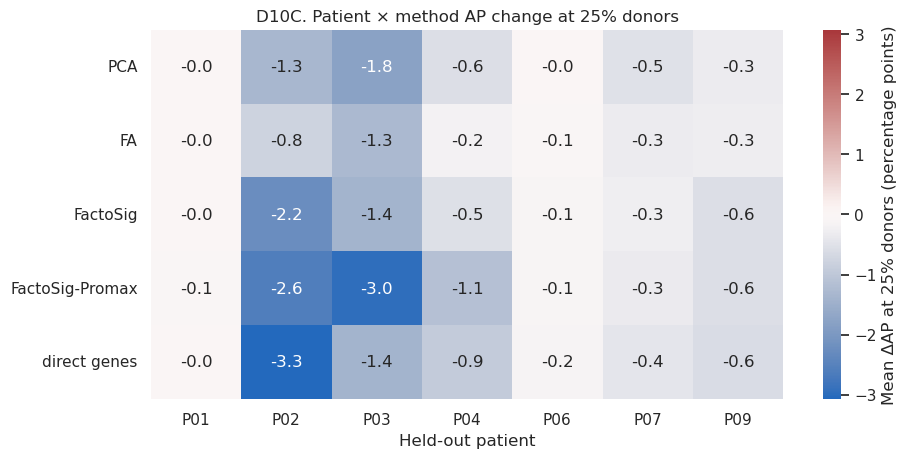

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10D_coefficient_stability_by_method.png


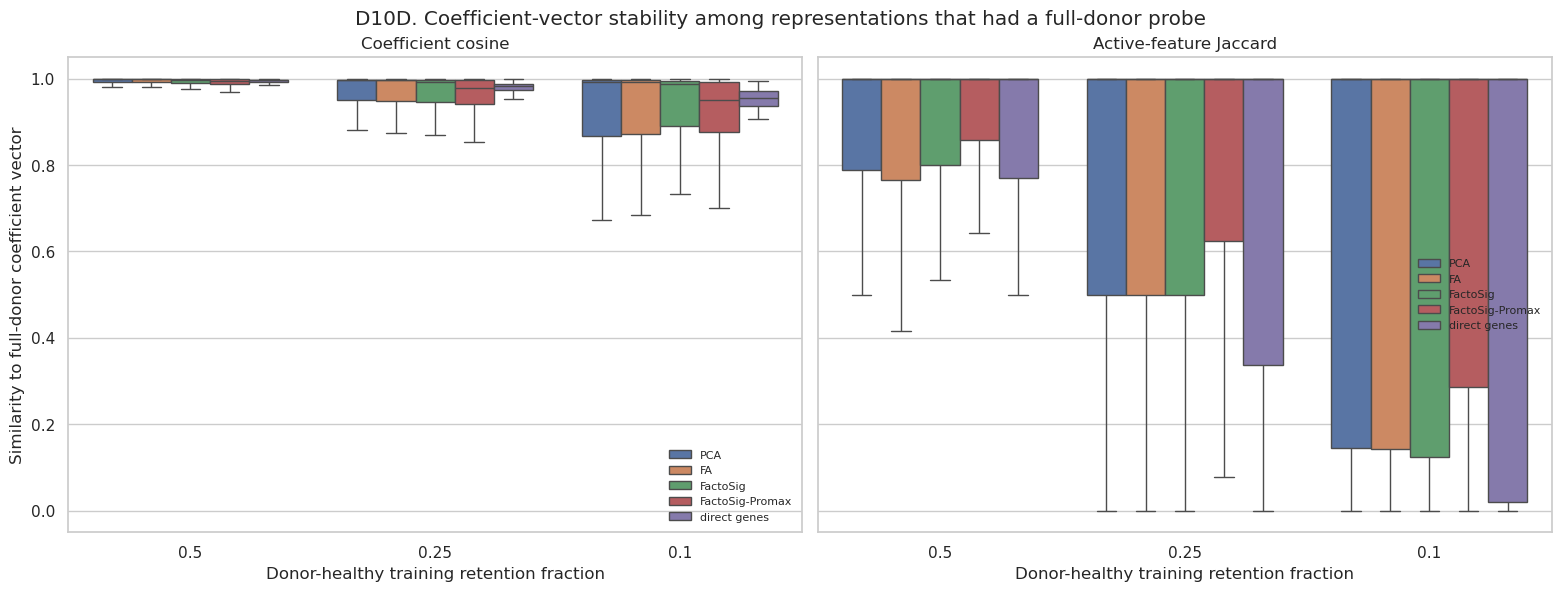

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16.8, 5.0), sharey=True, constrained_layout=True)
for ax, col, order, title in zip(
    axes,
    ["method_label", "penalty", "family_label"],
    [ [method_label(m) for m in METHOD_ORDER], PENALTY_ORDER, ["DR", "direct gene"] ],
    ["By Stage 1 method", "By frozen penalty", "DR vs direct gene"],
):
    sns.lineplot(
        data=d10_summary,
        x="donor_fraction",
        y="mean_delta_ap",
        hue=col,
        hue_order=order,
        estimator="mean",
        errorbar=("pi", 50),
        marker="o",
        ax=ax,
    )
    ax.axhline(0, color="0.4", lw=1, ls="--")
    ax.invert_xaxis()
    ax.set_xlabel("Donor retention fraction")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Mean held-out ΔAP vs full donors")
fig.suptitle("D10B. Landscape AP change (line = mean over representations; band = 25–75%)")
save_figure(fig, "D10B_landscape_ap_change")
plt.show()

method_patient_25 = (
    d10.loc[d10["donor_fraction"].eq(0.25)]
    .groupby(["method_label", "heldout_patient"], as_index=False)
    .agg(mean_delta_ap=("delta_heldout_auprc_vs_full_donor", "mean"))
)
method_patient_matrix = (
    method_patient_25.pivot(index="method_label", columns="heldout_patient", values="mean_delta_ap")
    .reindex(index=[method_label(m) for m in METHOD_ORDER], columns=SUPPORTED_PATIENTS)
)
vmax = max(float(np.nanpercentile(np.abs(method_patient_matrix.to_numpy()), 98)), 0.005)
fig, ax = plt.subplots(figsize=(10.2, 4.8))
sns.heatmap(100 * method_patient_matrix, annot=True, fmt=".1f", cmap="vlag", center=0,
            vmin=-100 * vmax, vmax=100 * vmax,
            cbar_kws={"label": "Mean ΔAP at 25% donors (percentage points)"}, ax=ax)
ax.set_xlabel("Held-out patient")
ax.set_ylabel("")
ax.set_title("D10C. Patient × method AP change at 25% donors")
save_figure(fig, "D10C_method_patient_ap_change_25pct")
plt.show()

stable_for_vector = d10_stability.loc[
    d10_stability["donor_fraction"].lt(1) & d10_stability["had_full_donor_probe"]
].copy()
stability_long = pd.concat(
    [
        stable_for_vector[["method_label", "donor_fraction", "coefficient_cosine_vs_full_donor"]]
        .rename(columns={"coefficient_cosine_vs_full_donor": "stability"})
        .assign(metric="Coefficient cosine"),
        stable_for_vector[["method_label", "donor_fraction", "active_feature_jaccard_vs_full_donor"]]
        .rename(columns={"active_feature_jaccard_vs_full_donor": "stability"})
        .assign(metric="Active-feature Jaccard"),
    ],
    ignore_index=True,
)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8), sharey=True, constrained_layout=True)
for ax, metric in zip(axes, ["Coefficient cosine", "Active-feature Jaccard"]):
    sns.boxplot(
        data=stability_long.loc[stability_long["metric"].eq(metric)],
        x="donor_fraction",
        y="stability",
        hue="method_label",
        hue_order=[method_label(m) for m in METHOD_ORDER],
        order=[0.5, 0.25, 0.1],
        showfliers=False,
        ax=ax,
    )
    ax.set_xlabel("Donor-healthy training retention fraction")
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(metric)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("Similarity to full-donor coefficient vector")
fig.suptitle("D10D. Coefficient-vector stability among representations that had a full-donor probe")
save_figure(fig, "D10D_coefficient_stability_by_method")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10F_active_coefficient_count_by_method.png


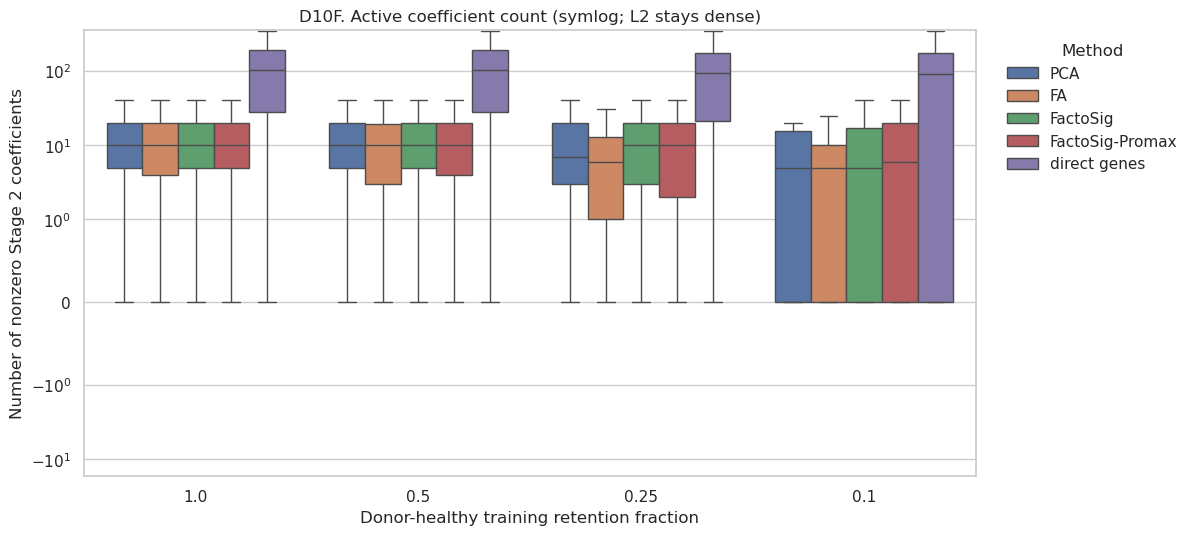

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10H_mean_lift_by_method.png


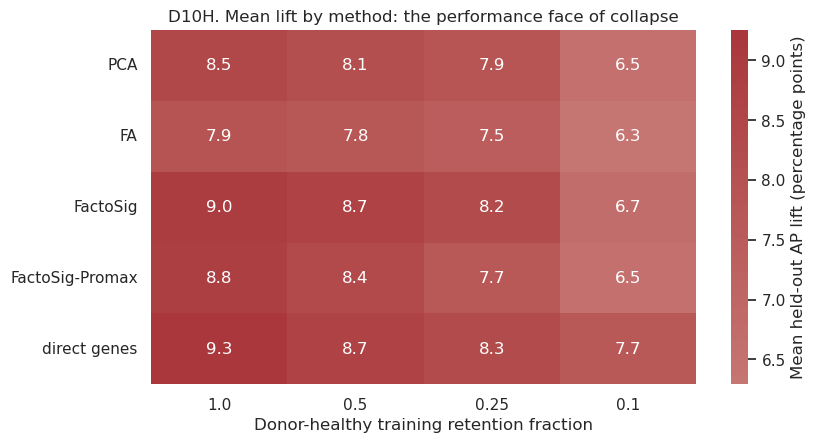

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10I_collapse_vs_delta_ap_25pct.png


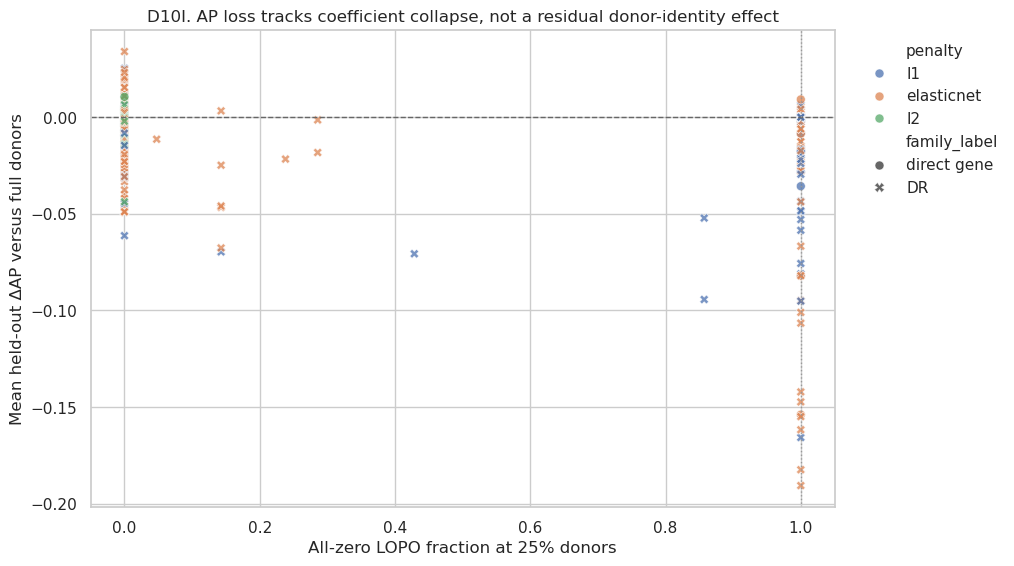

Spearman(collapse, ΔAP) at 25% among 681 targets: -0.17472079621631692
Among L2 only: collapse is constant (all zero); Spearman is undefined.
/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D10J_best_dr_vs_direct_25pct.png


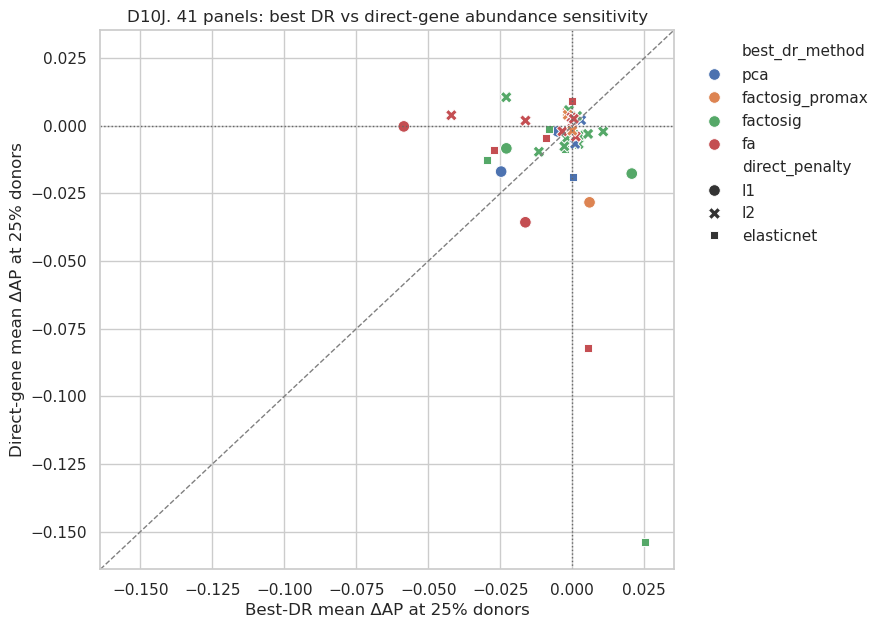

Paired panels: 41 / 41
Panels where best DR is more negative than direct at 25%: 22

L2 representations (no collapse): most negative ΔAP at 25%


,target_label,method_label,n_features,mean_delta_ap,worst_delta_ap,mean_lift
2525,proliferation metabolism | FactoSig-Promax10,FactoSig-Promax,10,-0.043741,-0.150502,0.100474
1033,myc targets v1 | FactoSig-Promax10,FactoSig-Promax,10,-0.019584,-0.065751,0.038249
2641,stress arrest | PCA40,PCA,40,-0.013977,-0.034994,0.179782
1961,interferon signaling | FactoSig-Promax10,FactoSig-Promax,10,-0.012658,-0.077658,0.063780
501,glycolysis | FactoSig-Promax10,FactoSig-Promax,10,-0.012295,-0.042403,0.100056
2097,mhc class ii antigen presentation | FactoSig-Promax10,FactoSig-Promax,10,-0.009883,-0.038110,0.037105
2377,cytokine jak stat | PCA40,PCA,40,-0.009714,-0.070789,0.184499
1029,myc targets v1 | direct genes,direct genes,195,-0.009628,-0.064636,0.073792
781,inflammatory response | FactoSig-Promax40,FactoSig-Promax,40,-0.009596,-0.029672,0.186967
2625,stress arrest | FA40,FA,40,-0.008781,-0.045664,0.195069


L2 representations: least negative / positive ΔAP at 25%


,target_label,method_label,n_features,mean_delta_ap,worst_delta_ap,mean_lift
2409,inflammatory interferon | FactoSig20,FactoSig,20,0.006531,-0.007206,0.175850
1657,jak stat signaling pathway | FactoSig20,FactoSig,20,0.006765,-0.000801,0.126207
1385,tgf beta signaling | FactoSig20,FactoSig,20,0.009350,-0.002407,0.085504
901,interferon gamma response | FactoSig-Promax20,FactoSig-Promax,20,0.009483,-0.014304,0.126896
2721,Stress arrest | direct genes,direct genes,685,0.010513,-0.014758,0.204511
2393,inflammatory interferon | FactoSig-Promax20,FactoSig-Promax,20,0.010871,-0.005939,0.211844
729,il6 jak stat3 signaling | FactoSig40,FactoSig,40,0.011487,-0.000371,0.113409
29,allograft rejection | FactoSig-Promax20,FactoSig-Promax,20,0.012411,-0.004409,0.164748


In [7]:
fig, ax = plt.subplots(figsize=(11.5, 5.8))
sns.boxplot(
    data=d10,
    x="donor_fraction",
    y="active_coefficient_count",
    hue="method_label",
    hue_order=[method_label(m) for m in METHOD_ORDER],
    order=DONOR_FRACTIONS,
    showfliers=False,
    ax=ax,
)
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("Number of nonzero Stage 2 coefficients")
ax.set_title("D10F. Active coefficient count (symlog; L2 stays dense)")
ax.legend(title="Method", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure(fig, "D10F_active_coefficient_count_by_method")
plt.show()

lift_matrix = (
    d10_summary.groupby(["method_label", "donor_fraction"], observed=True)["mean_lift"]
    .mean()
    .unstack()
    .reindex(index=[method_label(m) for m in METHOD_ORDER], columns=DONOR_FRACTIONS)
)
fig, ax = plt.subplots(figsize=(8.8, 4.6))
sns.heatmap(100 * lift_matrix, annot=True, fmt=".1f", cmap="vlag", center=0,
            cbar_kws={"label": "Mean held-out AP lift (percentage points)"}, ax=ax)
ax.set_xlabel("Donor-healthy training retention fraction")
ax.set_ylabel("")
ax.set_title("D10H. Mean lift by method: the performance face of collapse")
save_figure(fig, "D10H_mean_lift_by_method")
plt.show()

at_25 = d10_summary.loc[d10_summary["donor_fraction"].eq(0.25)].copy()
fig, ax = plt.subplots(figsize=(9.6, 6.2))
sns.scatterplot(
    data=at_25,
    x="collapse",
    y="mean_delta_ap",
    hue="penalty",
    hue_order=PENALTY_ORDER,
    style="family_label",
    alpha=0.75,
    s=42,
    ax=ax,
)
ax.axhline(0, color="0.4", lw=1, ls="--")
ax.axvline(1.0, color="0.6", lw=1, ls=":")
ax.set_xlabel("All-zero LOPO fraction at 25% donors")
ax.set_ylabel("Mean held-out ΔAP versus full donors")
ax.set_title("D10I. AP loss tracks coefficient collapse, not a residual donor-identity effect")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure(fig, "D10I_collapse_vs_delta_ap_25pct")
plt.show()
print("Spearman(collapse, ΔAP) at 25% among 681 targets:",
      float(at_25["collapse"].corr(at_25["mean_delta_ap"], method="spearman")))
l2_at_25 = at_25.loc[at_25["penalty"].eq("l2")]
if l2_at_25["collapse"].nunique() > 1:
    print("Among L2 only:", float(l2_at_25["collapse"].corr(l2_at_25["mean_delta_ap"], method="spearman")))
else:
    print("Among L2 only: collapse is constant (all zero); Spearman is undefined.")

best_lookup = d9.set_index("stage0_panel_id")
paired_rows = []
for panel_id, best_row in best_lookup.iterrows():
    best_id = best_row["best_dr_representation_id"]
    direct_id = best_row["representation_id"]
    best_metrics = at_25.loc[at_25["representation_id"].eq(best_id)]
    direct_metrics = at_25.loc[at_25["representation_id"].eq(direct_id)]
    if best_metrics.empty or direct_metrics.empty:
        continue
    paired_rows.append(
        {
            "stage0_panel_id": panel_id,
            "short_panel_label": best_row["short_panel_label"],
            "best_dr_method": best_row["best_dr_method"],
            "best_dr_k": best_row["best_dr_k"],
            "best_dr_delta_ap": float(best_metrics["mean_delta_ap"].iloc[0]),
            "best_dr_collapse": float(best_metrics["collapse"].iloc[0]),
            "direct_delta_ap": float(direct_metrics["mean_delta_ap"].iloc[0]),
            "direct_collapse": float(direct_metrics["collapse"].iloc[0]),
            "direct_penalty": str(direct_metrics["penalty"].iloc[0]),
        }
    )
paired = pd.DataFrame(paired_rows)
paired["dr_more_negative"] = paired["best_dr_delta_ap"] < paired["direct_delta_ap"]
paired_path = write_csv(paired, "fixed_basis_best_dr_vs_direct_25pct.csv")
fig, ax = plt.subplots(figsize=(7.4, 7.0))
sns.scatterplot(
    data=paired,
    x="best_dr_delta_ap",
    y="direct_delta_ap",
    hue="best_dr_method",
    style="direct_penalty",
    s=70,
    ax=ax,
)
lims = [
    min(paired["best_dr_delta_ap"].min(), paired["direct_delta_ap"].min()) - 0.01,
    max(paired["best_dr_delta_ap"].max(), paired["direct_delta_ap"].max()) + 0.01,
]
ax.plot(lims, lims, color="0.5", lw=1, ls="--")
ax.axhline(0, color="0.4", lw=1, ls=":")
ax.axvline(0, color="0.4", lw=1, ls=":")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Best-DR mean ΔAP at 25% donors")
ax.set_ylabel("Direct-gene mean ΔAP at 25% donors")
ax.set_title("D10J. 41 panels: best DR vs direct-gene abundance sensitivity")
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure(fig, "D10J_best_dr_vs_direct_25pct")
plt.show()
print(f"Paired panels: {len(paired)} / 41")
print("Panels where best DR is more negative than direct at 25%:", int(paired["dr_more_negative"].sum()))

l2_25 = at_25.loc[at_25["penalty"].eq("l2")].sort_values("mean_delta_ap")
print("\nL2 representations (no collapse): most negative ΔAP at 25%")
display(l2_25.head(12)[["target_label", "method_label", "n_features", "mean_delta_ap", "worst_delta_ap", "mean_lift"]])
print("L2 representations: least negative / positive ΔAP at 25%")
display(l2_25.tail(8)[["target_label", "method_label", "n_features", "mean_delta_ap", "worst_delta_ap", "mean_lift"]])


## 5. D11 — limited PCA/FA basis refit (21 representations)

Same frozen method as v1: transductive PCA/FA on the retained cells, project all 60,118 cells,
Hungarian-align to the fraction-1 refit, then Stage 2 on the refit scores with frozen \(C\).

The v1 mistake (treating five “top” factors as drivers) is already corrected in the runner:
`is_supervised_factor` is any factor with nonzero mean \(|\beta|\) at full donor;
`is_driver_factor` is the single largest of those. Two D11 targets (MYC v2 FA10, NF-κB FA5)
have **no** supervised factor because they were already all-zero at full donor.

D11A is still not a Stage 1-stability curve. Where every LOPO fit is all-zero, \(\Delta\)AP equals
minus that method's full-donor mean lift. D11B/C measure the refit basis itself.


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D11A_basis_refit_ap_change.png


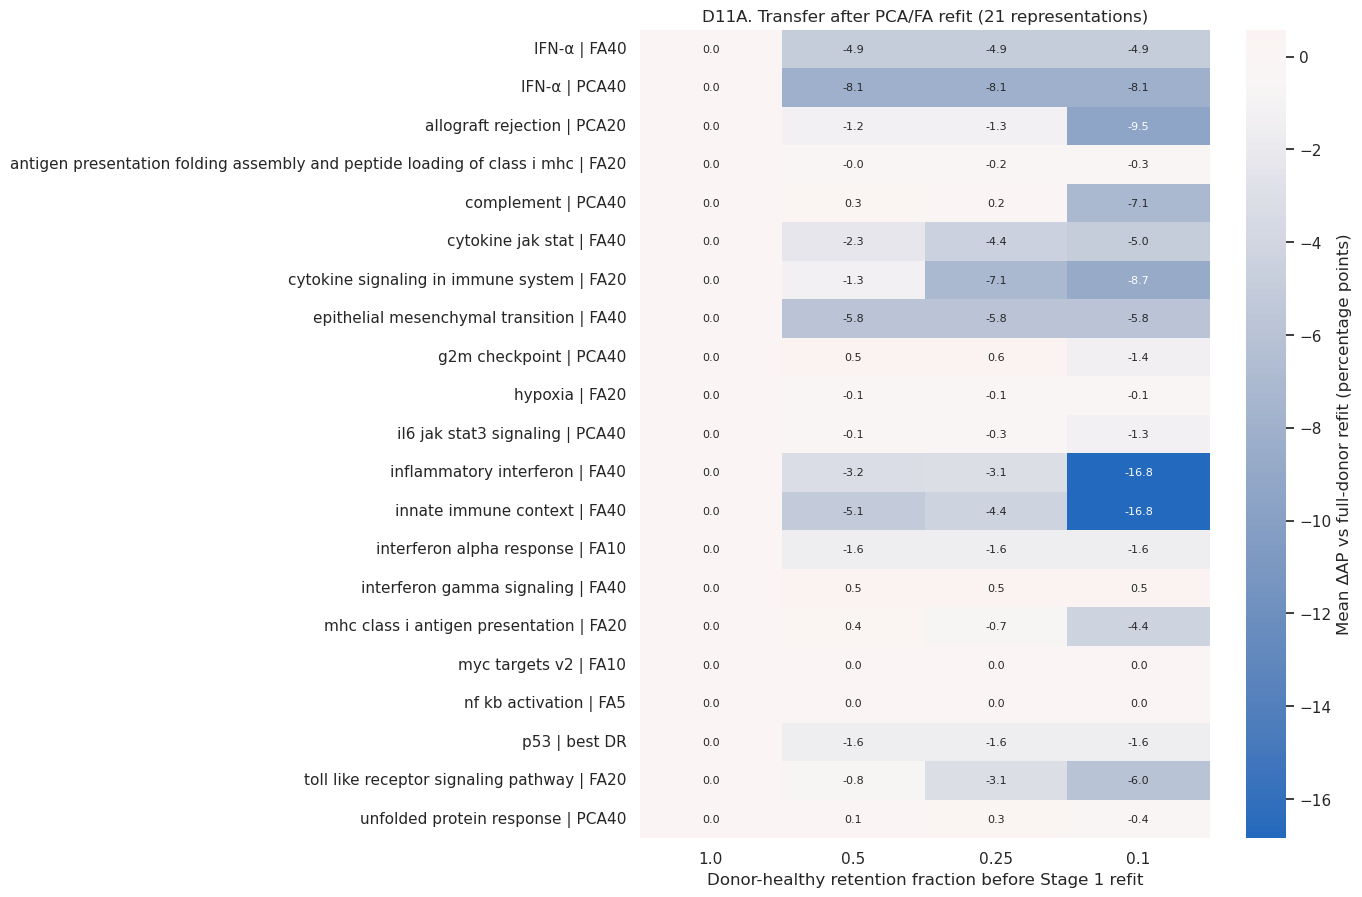

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D11A2_basis_refit_collapse.png


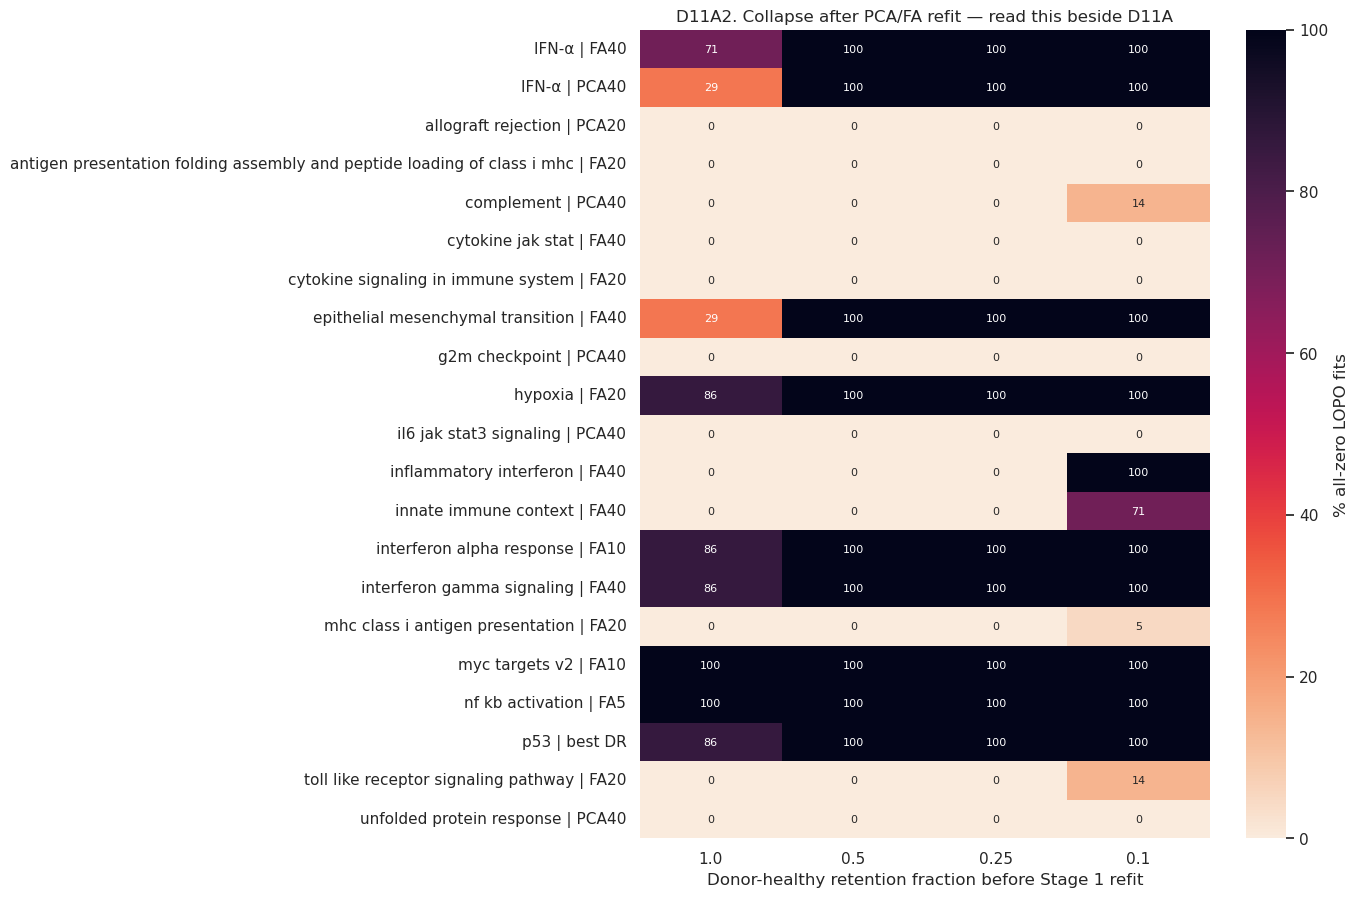

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D11B_factor_score_stability.png


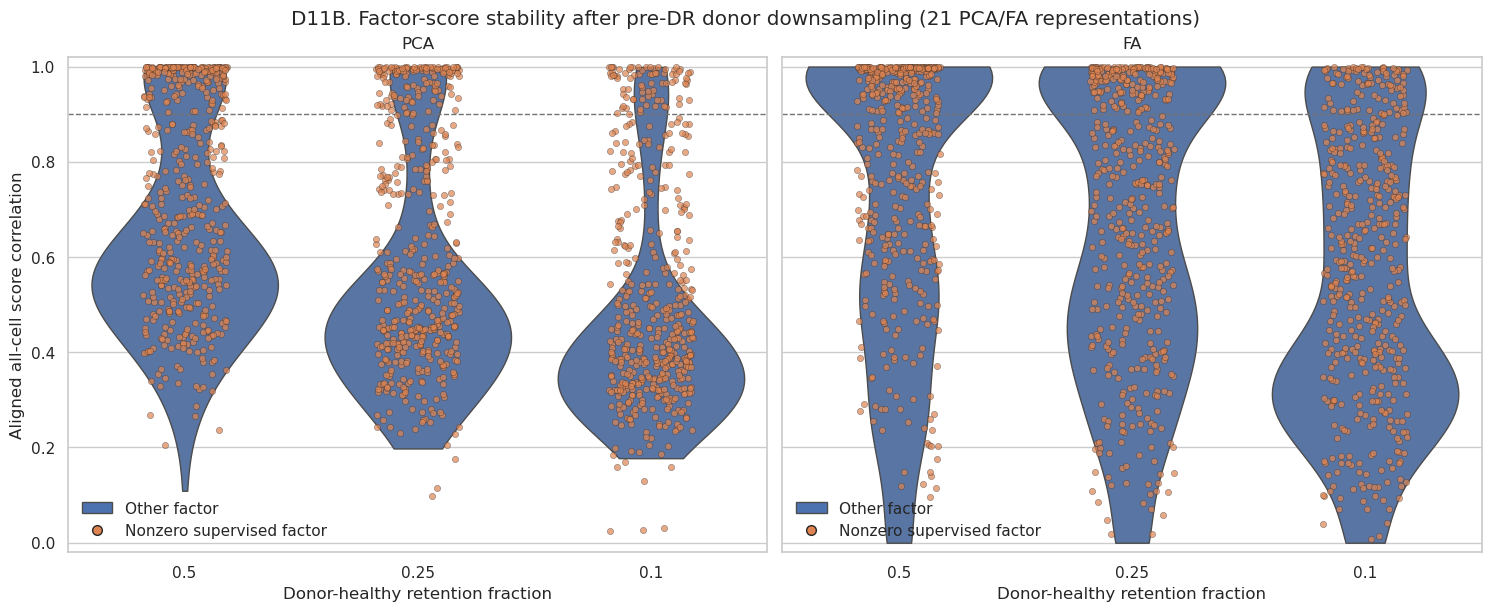

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D11C_supervised_factor_loading_stability.png


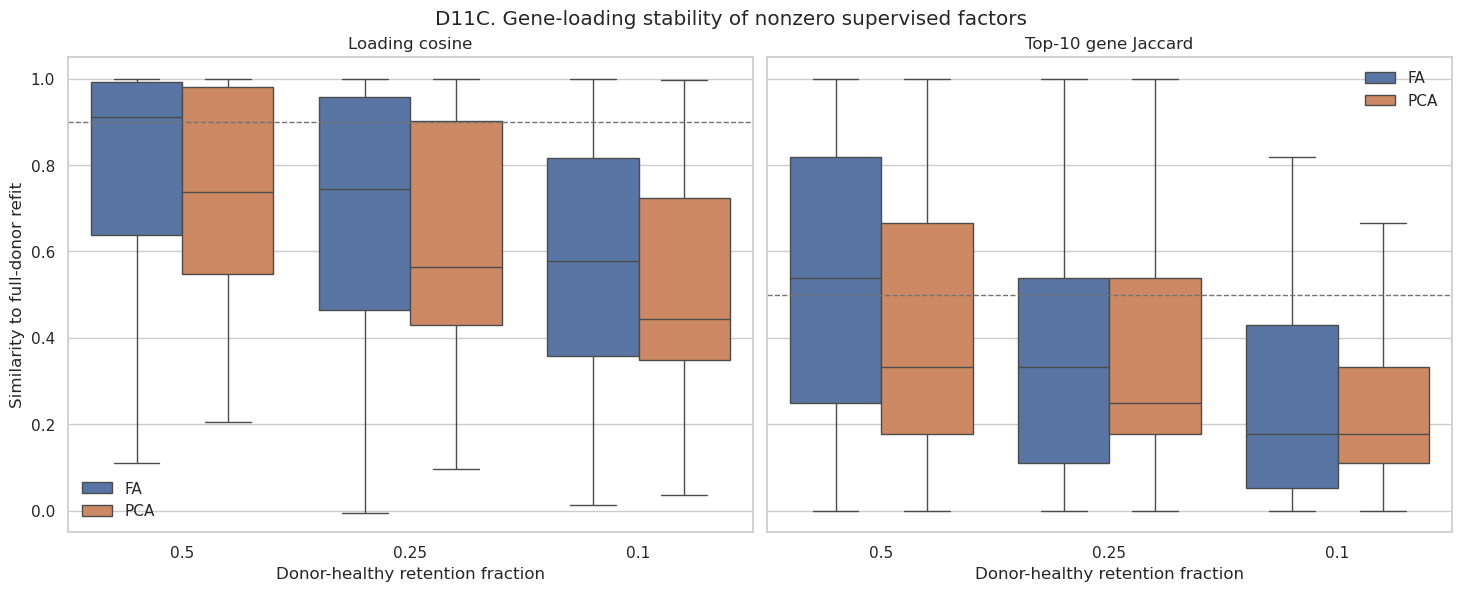

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D11D_patient_ap_change_25pct.png


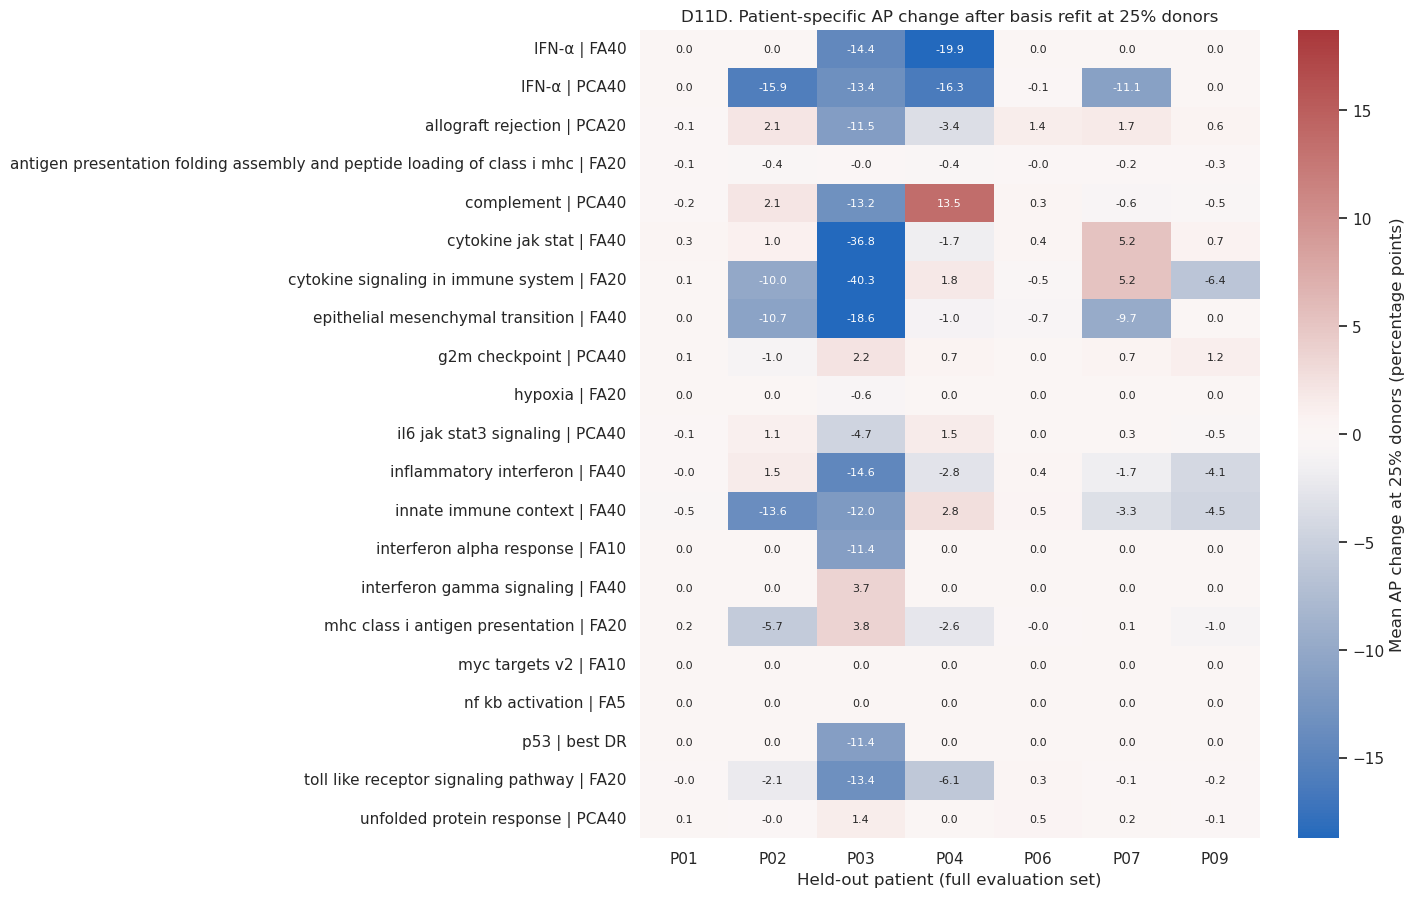

In [8]:
d11_summary = (
    d11.groupby(["target_id", "donor_fraction"], as_index=False)
    .agg(
        mean_delta_ap=("delta_heldout_auprc_vs_full_donor_basis", "mean"),
        worst_delta_ap=("delta_heldout_auprc_vs_full_donor_basis", "min"),
        mean_lift=("heldout_lift", "mean"),
        collapse=("zero_coefficient_solution", "mean"),
    )
    .merge(
        d11.drop_duplicates("target_id")[
            [
                "target_id",
                "target_label",
                "stage0_panel_id",
                "short_panel_label",
                "stage1_method",
                "method_label",
                "effective_k",
                "penalty",
            ]
        ],
        on="target_id",
        how="left",
        validate="many_to_one",
    )
)
d11_summary_path = write_csv(d11_summary, "basis_refit_donor_downsampling_summary.csv")

d11_ap_matrix = (
    d11_summary.pivot(index="target_label", columns="donor_fraction", values="mean_delta_ap")
    .reindex(columns=DONOR_FRACTIONS)
)
fig, ax = plt.subplots(figsize=(9.2, 10.5))
sns.heatmap(
    100 * d11_ap_matrix,
    annot=True,
    fmt=".1f",
    cmap="vlag",
    center=0,
    annot_kws={"size": 8},
    cbar_kws={"label": "Mean ΔAP vs full-donor refit (percentage points)"},
    ax=ax,
)
ax.set_xlabel("Donor-healthy retention fraction before Stage 1 refit")
ax.set_ylabel("")
ax.set_title("D11A. Transfer after PCA/FA refit (21 representations)")
save_figure(fig, "D11A_basis_refit_ap_change")
plt.show()

d11_collapse_matrix = (
    d11_summary.pivot(index="target_label", columns="donor_fraction", values="collapse")
    .reindex(columns=DONOR_FRACTIONS)
)
fig, ax = plt.subplots(figsize=(9.2, 10.5))
sns.heatmap(
    100 * d11_collapse_matrix,
    annot=True,
    fmt=".0f",
    cmap="rocket_r",
    vmin=0,
    vmax=100,
    annot_kws={"size": 8},
    cbar_kws={"label": "% all-zero LOPO fits"},
    ax=ax,
)
ax.set_xlabel("Donor-healthy retention fraction before Stage 1 refit")
ax.set_ylabel("")
ax.set_title("D11A2. Collapse after PCA/FA refit — read this beside D11A")
save_figure(fig, "D11A2_basis_refit_collapse")
plt.show()

stability_subset = d11_stability.loc[d11_stability["donor_fraction"].lt(1)].copy()
stability_subset["factor_role"] = np.where(
    stability_subset["is_supervised_factor"], "Nonzero supervised factor", "Other factor"
)
fig, axes = plt.subplots(1, 2, figsize=(14.8, 6.0), sharey=True, constrained_layout=True)
for ax, method_name in zip(axes, ["pca", "fa"]):
    data = stability_subset.loc[stability_subset["stage1_method"].eq(method_name)]
    other = data.loc[data["factor_role"].eq("Other factor")]
    supervised = data.loc[data["factor_role"].eq("Nonzero supervised factor")]
    sns.violinplot(
        data=other, x="donor_fraction", y="absolute_score_correlation", order=FRACTION_ORDER,
        color=ROLE_PALETTE["Other factor"], inner=None, cut=0, density_norm="width", linewidth=1.0, ax=ax,
    )
    sns.stripplot(
        data=supervised, x="donor_fraction", y="absolute_score_correlation", order=FRACTION_ORDER,
        color=ROLE_PALETTE["Nonzero supervised factor"], size=4.5, jitter=0.18, alpha=0.7,
        edgecolor="0.15", linewidth=0.3, ax=ax, zorder=3,
    )
    ax.axhline(FACTOR_SIMILARITY_GUIDE, color="0.45", lw=1, ls="--")
    ax.set_xlabel("Donor-healthy retention fraction")
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(method_name.upper())
    ax.legend(
        handles=[
            Patch(facecolor=ROLE_PALETTE["Other factor"], edgecolor="0.3", label="Other factor"),
            Line2D([0], [0], marker="o", color="none", markerfacecolor=ROLE_PALETTE["Nonzero supervised factor"],
                   markeredgecolor="0.15", markersize=7, label="Nonzero supervised factor"),
        ],
        frameon=False,
    )
axes[0].set_ylabel("Aligned all-cell score correlation")
fig.suptitle("D11B. Factor-score stability after pre-DR donor downsampling (21 PCA/FA representations)")
save_figure(fig, "D11B_factor_score_stability")
plt.show()

driver_stability = stability_subset.loc[stability_subset["is_supervised_factor"]].copy()
driver_long = pd.concat(
    [
        driver_stability[["method_label", "donor_fraction", "loading_cosine_common_gene_scale"]]
        .rename(columns={"loading_cosine_common_gene_scale": "stability"})
        .assign(metric="Loading cosine"),
        driver_stability[["method_label", "donor_fraction", "top10_gene_jaccard"]]
        .rename(columns={"top10_gene_jaccard": "stability"})
        .assign(metric="Top-10 gene Jaccard"),
    ],
    ignore_index=True,
)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), sharey=True, constrained_layout=True)
for ax, metric in zip(axes, ["Loading cosine", "Top-10 gene Jaccard"]):
    sns.boxplot(
        data=driver_long.loc[driver_long["metric"].eq(metric)],
        x="donor_fraction",
        y="stability",
        hue="method_label",
        order=FRACTION_ORDER,
        showfliers=False,
        ax=ax,
    )
    ax.axhline(FACTOR_SIMILARITY_GUIDE if metric == "Loading cosine" else TOP_GENE_JACCARD_GUIDE,
               color="0.45", lw=1, ls="--")
    ax.set_xlabel("Donor-healthy retention fraction")
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(metric)
    ax.legend(frameon=False)
axes[0].set_ylabel("Similarity to full-donor refit")
fig.suptitle("D11C. Gene-loading stability of nonzero supervised factors")
save_figure(fig, "D11C_supervised_factor_loading_stability")
plt.show()

d11_25_patient = (
    d11.loc[d11["donor_fraction"].eq(0.25)]
    .groupby(["target_label", "heldout_patient"], as_index=False)
    .agg(mean_delta_ap=("delta_heldout_auprc_vs_full_donor_basis", "mean"))
)
d11_25_matrix = d11_25_patient.pivot(index="target_label", columns="heldout_patient", values="mean_delta_ap").reindex(columns=SUPPORTED_PATIENTS)
vmax = max(float(np.nanpercentile(np.abs(d11_25_matrix.to_numpy()), 98)), 0.005)
fig, ax = plt.subplots(figsize=(10.0, 10.5))
sns.heatmap(100 * d11_25_matrix, annot=True, fmt=".1f", cmap="vlag", center=0,
            vmin=-100 * vmax, vmax=100 * vmax, annot_kws={"size": 8},
            cbar_kws={"label": "Mean AP change at 25% donors (percentage points)"}, ax=ax)
ax.set_xlabel("Held-out patient (full evaluation set)")
ax.set_ylabel("")
ax.set_title("D11D. Patient-specific AP change after basis refit at 25% donors")
save_figure(fig, "D11D_patient_ap_change_25pct")
plt.show()


/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D11E_ifna_factor_score_stability.png


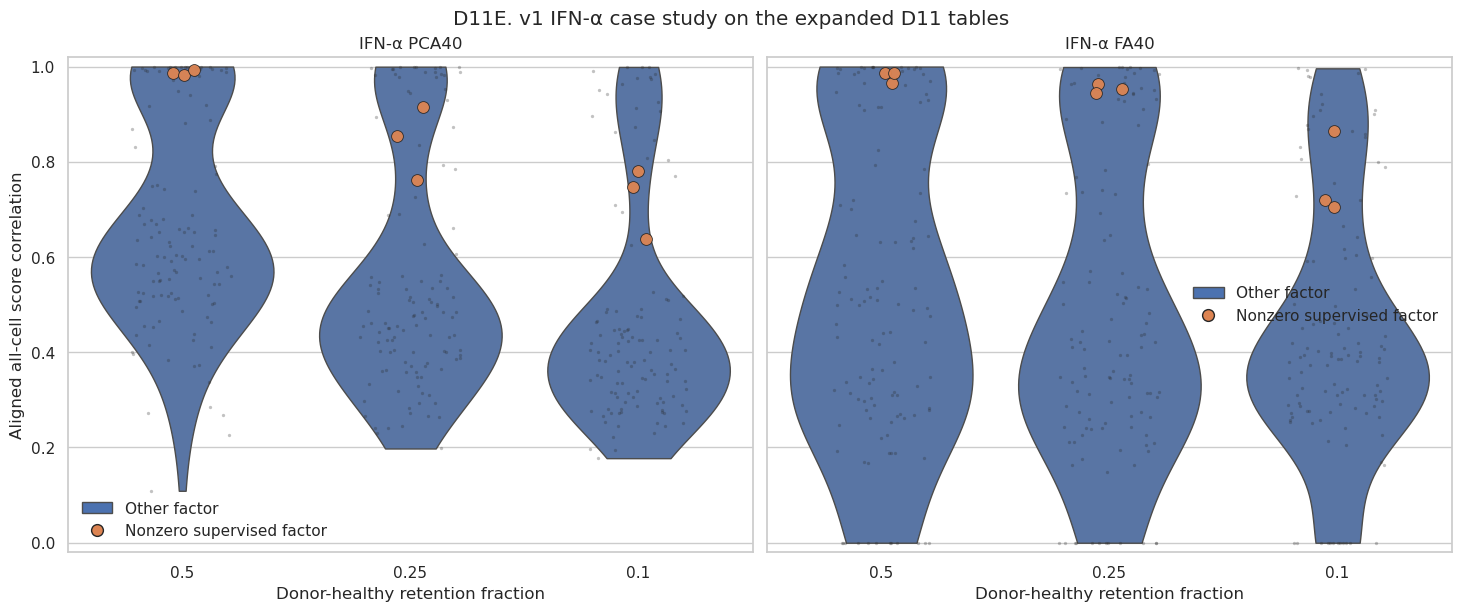

/home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/figures/stage2_diagnostic/donor_sensitivity_v2/D11E2_ifna_driver_loading_stability.png


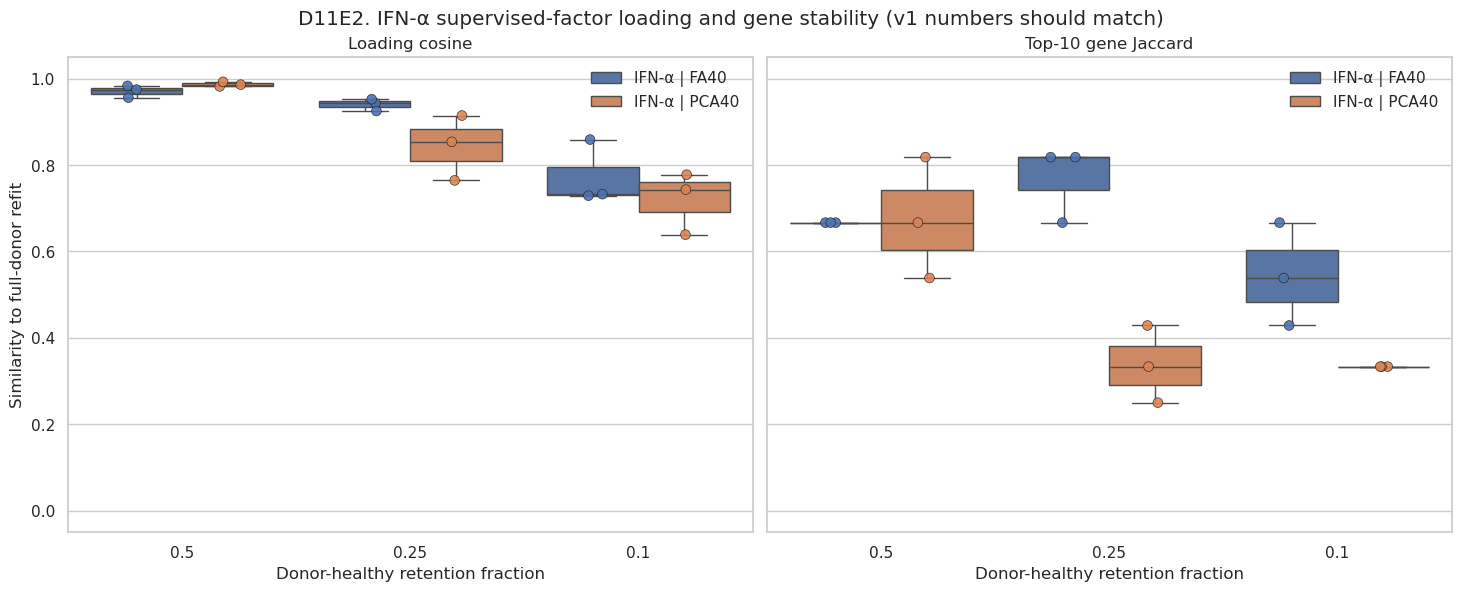

IFN-α supervised-factor stability at 25% (compare to v1 findings):


,target_label,median_score_correlation,median_loading_cosine,median_top10_gene_jaccard
3,IFN-α | FA40,0.951913,0.943101,0.818182
9,IFN-α | PCA40,0.854429,0.853678,0.333333



All 21 D11 targets: supervised-factor median stability at 25%


,target_label,stage1_method,median_score_correlation,median_loading_cosine,median_top10_gene_jaccard
71,unfolded protein response | PCA40,pca,0.451320,0.448213,0.176471
134,innate immune context | FA40,fa,0.491287,0.451174,0.111111
44,g2m checkpoint | PCA40,pca,0.539241,0.534550,0.250000
56,il6 jak stat3 signaling | PCA40,pca,0.564008,0.566764,0.333333
86,antigen presentation folding assembly and peptide loading of class i mhc | FA20,fa,0.567101,0.577586,0.333333
28,complement | PCA40,pca,0.582039,0.577056,0.176471
124,inflammatory interferon | FA40,fa,0.645928,0.627858,0.176471
116,cytokine jak stat | FA40,fa,0.685793,0.635257,0.176471
133,innate immune context | FA40,fa,0.721229,0.719016,0.250000
79,toll like receptor signaling pathway | FA20,fa,0.747253,0.710104,0.428571


D11 targets with no supervised factor (already all-zero at full donor):


,target_label,penalty,C,effective_k
9,myc targets v2 | FA10,l1,0.0001,10
17,nf kb activation | FA5,l1,0.0001,5


In [9]:
ifna_stability = d11_stability.loc[d11_stability["target_id"].isin(V1_BASIS_TARGET_IDS)].copy()
ifna_subset = ifna_stability.loc[ifna_stability["donor_fraction"].lt(1)].copy()
ifna_subset["factor_role"] = np.where(ifna_subset["is_supervised_factor"], "Nonzero supervised factor", "Other factor")
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.0), sharey=True, constrained_layout=True)
for ax, method_name, title in zip(axes, ["pca", "fa"], ["PCA40", "FA40"]):
    data = ifna_subset.loc[ifna_subset["stage1_method"].eq(method_name)]
    other = data.loc[data["factor_role"].eq("Other factor")]
    driver = data.loc[data["factor_role"].eq("Nonzero supervised factor")]
    sns.violinplot(
        data=other, x="donor_fraction", y="absolute_score_correlation", order=FRACTION_ORDER,
        color=ROLE_PALETTE["Other factor"], inner=None, cut=0, density_norm="width", linewidth=1.0, ax=ax,
    )
    sns.stripplot(
        data=other, x="donor_fraction", y="absolute_score_correlation", order=FRACTION_ORDER,
        color="0.15", size=2.4, jitter=0.22, alpha=0.28, ax=ax,
    )
    sns.stripplot(
        data=driver, x="donor_fraction", y="absolute_score_correlation", order=FRACTION_ORDER,
        color=ROLE_PALETTE["Nonzero supervised factor"], size=8.5, jitter=0.06, alpha=0.95,
        edgecolor="0.15", linewidth=0.6, ax=ax, zorder=3,
    )
    ax.set_xlabel("Donor-healthy retention fraction")
    ax.set_ylim(-0.02, 1.02)
    ax.set_title("IFN-α " + title)
    ax.legend(
        handles=[
            Patch(facecolor=ROLE_PALETTE["Other factor"], edgecolor="0.3", label="Other factor"),
            Line2D([0], [0], marker="o", color="none", markerfacecolor=ROLE_PALETTE["Nonzero supervised factor"],
                   markeredgecolor="0.15", markersize=8.5, label="Nonzero supervised factor"),
        ],
        frameon=False,
    )
axes[0].set_ylabel("Aligned all-cell score correlation")
fig.suptitle("D11E. v1 IFN-α case study on the expanded D11 tables")
save_figure(fig, "D11E_ifna_factor_score_stability")
plt.show()

ifna_driver = ifna_subset.loc[ifna_subset["is_supervised_factor"]].copy()
ifna_driver_long = pd.concat(
    [
        ifna_driver[["target_label", "donor_fraction", "loading_cosine_common_gene_scale"]]
        .rename(columns={"loading_cosine_common_gene_scale": "stability"})
        .assign(metric="Loading cosine"),
        ifna_driver[["target_label", "donor_fraction", "top10_gene_jaccard"]]
        .rename(columns={"top10_gene_jaccard": "stability"})
        .assign(metric="Top-10 gene Jaccard"),
    ],
    ignore_index=True,
)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), sharey=True, constrained_layout=True)
for ax, metric in zip(axes, ["Loading cosine", "Top-10 gene Jaccard"]):
    sns.boxplot(
        data=ifna_driver_long.loc[ifna_driver_long["metric"].eq(metric)],
        x="donor_fraction",
        y="stability",
        hue="target_label",
        order=FRACTION_ORDER,
        showfliers=False,
        ax=ax,
    )
    sns.stripplot(
        data=ifna_driver_long.loc[ifna_driver_long["metric"].eq(metric)],
        x="donor_fraction",
        y="stability",
        hue="target_label",
        order=FRACTION_ORDER,
        dodge=True,
        jitter=0.12,
        size=7,
        alpha=0.9,
        edgecolor="0.15",
        linewidth=0.5,
        ax=ax,
        legend=False,
    )
    ax.set_xlabel("Donor-healthy retention fraction")
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(metric)
    ax.legend(frameon=False)
axes[0].set_ylabel("Similarity to full-donor refit")
fig.suptitle("D11E2. IFN-α supervised-factor loading and gene stability (v1 numbers should match)")
save_figure(fig, "D11E2_ifna_driver_loading_stability")
plt.show()

factor_summary = (
    d11_stability.loc[d11_stability["donor_fraction"].lt(1)]
    .groupby(
        ["target_id", "target_label", "stage1_method", "donor_fraction", "is_supervised_factor", "is_driver_factor"],
        as_index=False,
    )
    .agg(
        median_score_correlation=("absolute_score_correlation", "median"),
        median_loading_cosine=("loading_cosine_common_gene_scale", "median"),
        median_top10_gene_jaccard=("top10_gene_jaccard", "median"),
        n_factor_seed_rows=("reference_factor", "size"),
    )
)
factor_summary_path = write_csv(factor_summary, "basis_refit_factor_stability_summary.csv")

ifna_25 = factor_summary.loc[
    factor_summary["target_id"].isin(V1_BASIS_TARGET_IDS)
    & factor_summary["donor_fraction"].eq(0.25)
    & factor_summary["is_supervised_factor"]
]
print("IFN-α supervised-factor stability at 25% (compare to v1 findings):")
display(ifna_25[["target_label", "median_score_correlation", "median_loading_cosine", "median_top10_gene_jaccard"]])

print("\nAll 21 D11 targets: supervised-factor median stability at 25%")
display(
    factor_summary.loc[
        factor_summary["donor_fraction"].eq(0.25) & factor_summary["is_supervised_factor"]
    ][["target_label", "stage1_method", "median_score_correlation", "median_loading_cosine", "median_top10_gene_jaccard"]]
    .sort_values("median_score_correlation")
)
print("D11 targets with no supervised factor (already all-zero at full donor):")
no_supervised = sorted(set(d11_manifest["target_id"]) - set(
    d11_stability.loc[d11_stability["is_supervised_factor"], "target_id"]
))
display(d11_manifest.loc[d11_manifest["target_id"].isin(no_supervised), ["target_label", "penalty", "C", "effective_k"]])


## 6. Interpretation, plot contracts, and findings

Descriptive review guides, not inferential cutoffs: AP change of 0.02, aligned score/loading
similarity of 0.90, top-10 gene Jaccard of 0.50.

A performance change can arise from (i) less healthy-cell support, (ii) a shifted Stage 1 basis,
or (iii) a fixed regularization setting crossing to the all-zero solution. D10E/D10I make (iii)
explicit across 681 representations. An AP loss accompanied by coefficient collapse is **not**
evidence that the model learned donor identity.

L2 representations never hit \(\boldsymbol\beta=\mathbf 0\) under this frozen \(C\). They are the cleanest
supervised abundance-sensitivity slice in this run. They are still not a donor-origin test:
recipient-healthy support remains 50 cells, and \(C\) is not reselected inside each mask.


In [10]:
def plot_contract(plot_id: str, decision: str, comparison: str, held_fixed: str, denominator: str,
                  uncertainty: str, success: str, failure: str, caveat: str) -> dict[str, str]:
    return {
        "plot_id": plot_id,
        "status": "diagnostic_not_manuscript_ready",
        "decision": decision,
        "comparison": comparison,
        "held_fixed": held_fixed,
        "denominator_or_unit": denominator,
        "uncertainty": uncertainty,
        "success_pattern": success,
        "failure_pattern": failure,
        "primary_caveat": caveat,
    }


plot_contracts = pd.DataFrame(
    [
        plot_contract("D10A", "Verify that the intervention changes only donor-healthy support.",
                      "Requested donor fraction versus actual retained donor cells.",
                      "All malignant and recipient-healthy cells; patient × predicted-cell-type stratification.",
                      "Cell count across the exact 60,118-cell cohort.",
                      "Three mask seeds for fractions below 1.",
                      "Monotone retained counts with invariant malignant/recipient counts.",
                      "Non-target cells removed or requested fractions not achieved.",
                      "Small strata retain at least five donor cells, so realized fractions differ slightly."),
        plot_contract("D10A2", "Show that donor downsampling is applied inside every patient × cell-type stratum.",
                      "Realized retention fraction at 25% donors, seed 42 (same mask as v1).",
                      "MIN_DONOR_CELLS_PER_STRATUM = 5; malignant and recipient-healthy cells are never dropped.",
                      "Kept / original donor-healthy cells in that stratum.",
                      "One representative mask seed.",
                      "Most large strata sit at 0.25.",
                      "Small strata sit above 0.25 or at 1.0 because of the 5-cell floor.",
                      "There is no size threshold that skips a cell type; every stratum is downsampled unless n ≤ 5."),
        plot_contract("D10E", "Separate regularization-path failure from donor-origin sensitivity at 681-target scale.",
                      "Mean all-zero LOPO fraction by method or penalty and donor fraction.",
                      "Selected global C/penalty and Stage 1 basis.",
                      "Percent of seven-patient × seed fits, then averaged over representations.",
                      "Descriptive fold/seed/target frequency.",
                      "Nonzero models remain estimable, especially L2.",
                      "Abrupt all-zero transition after any donor reduction, concentrated in L1.",
                      "Collapse diagnoses a fixed-C pathology; it does not identify the biological cause."),
        plot_contract("D10B", "Assess landscape supervised-model sensitivity to donor-healthy training abundance.",
                      "Mean full-held-out-patient AP change versus fraction 1, aggregated by method/penalty/family.",
                      "Stage 1 scores, global regularization, class weighting, full held-out evaluation.",
                      "AP difference; mean over representations, with a 25–75% band.",
                      "Patient, mask-seed, and representation variation; no inferential interval.",
                      "Changes remain near zero as donors are reduced, especially for L2.",
                      "Large negative changes concentrated where D10E reports collapse.",
                      "Inspect D10E/D10I before biological attribution."),
        plot_contract("D10I", "Test whether AP loss is the arithmetic of collapse.",
                      "Per-target collapse rate versus mean ΔAP at 25% donors.",
                      "Same frozen C and full held-out evaluation as D10B.",
                      "One point per representation.",
                      "Descriptive association across 681 dependent representations.",
                      "L2 points near x=0 with small ΔAP; collapsed L1 points at x=1 with ΔAP ≈ −full-donor lift.",
                      "Large ΔAP at x=0 would suggest abundance sensitivity without collapse.",
                      "This still does not reselect C, so it is not a donor-shortcut test."),
        plot_contract("D10J", "Compare best-DR and direct-gene abundance sensitivity within each of 41 panels.",
                      "Mean ΔAP at 25% donors for the D9 best-DR representation versus the panel's direct-gene baseline.",
                      "Frozen per-representation C; identical donor masks.",
                      "AP difference from each representation's own fraction-1 fit.",
                      "41 paired panels; winner's-curse still applies to 'best DR'.",
                      "Direct-gene and best-DR move together.",
                      "One family is systematically more negative after collapse is accounted for.",
                      "Best DR is still selected on pooled LOPO AP, not nested inside this sensitivity."),
        plot_contract("D11B", "Determine whether PCA/FA factor scores move when donor abundance changes before DR.",
                      "Hungarian-aligned refit factors versus the fraction-1 basis, 21 representations.",
                      "Same panel genes, K, Stage 1 seed, and all-cell projection set.",
                      "Absolute all-cell score correlation.",
                      "Distributions over factors, seeds, and supervised/other strata.",
                      "Supervised factors retain correlation at or above 0.90 at 50% and remain high at 25%.",
                      "Supervised factors lose one-to-one score correspondence.",
                      "Transductive alignment is descriptive and does not establish external reproducibility."),
        plot_contract("D11C", "Assess biological-gene grounding stability of supervised PCA/FA factors.",
                      "Aligned supervised-factor loadings versus fraction-1 in common gene coordinates.",
                      "Factors with nonzero mean absolute full-donor Stage 2 coefficient.",
                      "Loading cosine and top-10 absolute-loading gene Jaccard.",
                      "Distributions across supervised factors and mask seeds.",
                      "Loading cosine ≥0.90 and gene Jaccard ≥0.50 at moderate downsampling.",
                      "Low loading similarity or replacement of top genes.",
                      "Do not average in zero-coefficient factors; that was the v1 inflation error."),
        plot_contract("D11E", "Reproduce the v1 IFN-α PCA40/FA40 case study on the expanded tables.",
                      "Supervised-factor score, loading, and top-10 Jaccard at 25% donors.",
                      "Same 92 genes, K=40, frozen L1 C=1e-4.",
                      "Median over three mask seeds for the single supervised factor per method.",
                      "Three seeds only.",
                      "FA factor remains more stable than PCA at 25%, matching v1.",
                      "Numbers disagree with donor_sensitivity_v1 beyond the QA AP tolerance.",
                      "Stage 2 is still all-zero at ≤50% donors for both IFN-α methods."),
    ]
)
plot_contracts_path = write_csv(plot_contracts, "donor_sensitivity_v2_plot_contracts.csv")

at_25 = d10_summary.loc[d10_summary["donor_fraction"].eq(0.25)]
collapse_25 = d10_collapse.loc[d10_collapse["donor_fraction"].eq(0.25)]
n_allzero_25 = int(collapse_25["zero_solution_fraction"].eq(1.0).sum())
l2_delta = at_25.loc[at_25["penalty"].eq("l2"), "mean_delta_ap"]
l1_delta = at_25.loc[at_25["penalty"].eq("l1"), "mean_delta_ap"]
ifna_25 = factor_summary.loc[
    factor_summary["target_id"].isin(V1_BASIS_TARGET_IDS)
    & factor_summary["donor_fraction"].eq(0.25)
    & factor_summary["is_supervised_factor"]
].set_index("target_id")
d11_sup_25 = factor_summary.loc[
    factor_summary["donor_fraction"].eq(0.25) & factor_summary["is_supervised_factor"]
]
d11_pca_25 = d11_sup_25.loc[d11_sup_25["stage1_method"].eq("pca")]
d11_fa_25 = d11_sup_25.loc[d11_sup_25["stage1_method"].eq("fa")]

findings_lines = [
    "# Old34 donor-downsampling expansion (v2) findings",
    "",
    f"Generated: {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Design",
    "",
    f"- Exact binary MRD/CITE cohort: {N_CELLS:,} cells; {N_DONOR_HEALTHY:,} donor healthy, {N_RECIPIENT_HEALTHY} recipient healthy, {N_MALIGNANT:,} malignant.",
    f"- D10 fixed-basis: {d10['target_id'].nunique()} targets × {len(SUPPORTED_PATIENTS)} held-out patients × 10 donor-mask conditions = {len(d10):,} fits.",
    f"- D11 pre-DR: {d11['target_id'].nunique()} PCA/FA representations × 10 transductive basis refits; {len(d11):,} full-held-out Stage 2 evaluations.",
    "- Frozen method copied from stage2_old34_donor_downsampling_sensitivity.ipynb. Regularization is not reselected.",
    f"- v1 QA: D10 {qa_fixed['n_compared_rows']} rows, max |ΔAP| {qa_fixed['max_abs_ap_error']:.2e}; D11 {qa_basis['n_compared_rows']} rows, max |ΔAP| {qa_basis['max_abs_ap_error']:.2e}; collapse mismatches 0.",
    "",
    "## Collapse before AP",
    "",
    f"- {n_full_zero_targets} / 681 representations are already 100% all-zero at full donor (the empty supervised.csv files).",
    f"- At 25% donors, {n_allzero_25} / 681 representations are 100% all-zero.",
    f"- Mean collapse at 25%: L1 {float(collapse_25.loc[collapse_25['penalty'].eq('l1'), 'zero_solution_fraction'].mean()):.3f}; elastic-net {float(collapse_25.loc[collapse_25['penalty'].eq('elasticnet'), 'zero_solution_fraction'].mean()):.3f}; L2 {float(collapse_25.loc[collapse_25['penalty'].eq('l2'), 'zero_solution_fraction'].mean()):.3f}.",
    f"- Spearman(collapse, mean ΔAP) at 25% across 681 targets: {float(at_25['collapse'].corr(at_25['mean_delta_ap'], method='spearman')):.3f}.",
    "",
    "## Fixed-basis AP at 25% donor retention",
    "",
    f"- L1 mean ΔAP: {float(l1_delta.mean()):+.4f} (median {float(l1_delta.median()):+.4f}).",
    f"- L2 mean ΔAP: {float(l2_delta.mean()):+.4f} (median {float(l2_delta.median()):+.4f}); L2 never collapses.",
    f"- Direct-gene mean ΔAP: {float(at_25.loc[at_25['representation_family'].eq('direct_gene'), 'mean_delta_ap'].mean()):+.4f}.",
    f"- DR mean ΔAP: {float(at_25.loc[at_25['representation_family'].eq('dr'), 'mean_delta_ap'].mean()):+.4f}.",
    f"- Best-DR vs direct-gene pairs at 25%: {len(paired)} / 41 panels; best DR more negative in {int(paired['dr_more_negative'].sum())} / {len(paired)}.",
    "",
    "## D11 supervised-factor stability at 25%",
    "",
]
for target_id, row in ifna_25.iterrows():
    findings_lines.append(
        f"- {row['target_label']}: median score correlation {row['median_score_correlation']:.3f}, "
        f"loading cosine {row['median_loading_cosine']:.3f}, top-10 Jaccard {row['median_top10_gene_jaccard']:.3f}."
    )
findings_lines.extend(
    [
        f"- Across D11 PCA supervised factors: median score correlation {float(d11_pca_25['median_score_correlation'].median()):.3f}.",
        f"- Across D11 FA supervised factors: median score correlation {float(d11_fa_25['median_score_correlation'].median()):.3f}.",
        f"- D11 targets with no supervised factor: {', '.join(d11_manifest.loc[d11_manifest['target_id'].isin(no_supervised), 'target_label']) or 'none'}.",
        "",
        "## Interpretation boundary",
        "",
        "- Any AP loss accompanied by an all-zero coefficient transition is a fixed-regularization pathology and cannot be attributed to donor identity.",
        "- L2 targets provide the cleanest supervised abundance sensitivity because they do not cross an L1/elastic-net zero boundary.",
        "- Factor-score and loading stability are the relevant evidence for whether donor abundance materially changes the Stage 1 biological representation.",
        "- This expansion still does not establish donor-versus-recipient invariance; recipient-healthy support is too sparse for a balanced origin-stratified test.",
        "- Condition-specific C rescue remains the missing experiment for a donor-shortcut claim.",
    ]
)
findings_path = TABLE_DIR / "donor_sensitivity_v2_findings.md"
findings_path.write_text("\n".join(findings_lines) + "\n")
GENERATED_TABLES.append(findings_path)

ledger_records = []
for path in sorted(set(GENERATED_TABLES + GENERATED_FIGURES)):
    if not path.exists():
        continue
    if path.suffix.lower() in {".png", ".pdf"}:
        artifact_type = "figure"
    elif path.suffix.lower() == ".md":
        artifact_type = "report"
    else:
        artifact_type = "table_or_metadata"
    ledger_records.append(
        {
            "artifact_type": artifact_type,
            "relative_path": str(path.relative_to(EXP_DIR)),
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
            "producer_notebook": "scripts/mrd_stage0_2/notebooks/stage0_2/stage2_old34_donor_downsampling_sensitivity_v2.ipynb",
        }
    )
ledger = pd.DataFrame(ledger_records)
ledger_path = write_csv(ledger, "donor_sensitivity_v2_analysis_artifact_ledger.csv")

print("Findings:", findings_path)
print(findings_path.read_text())
print("Figures written:", len(GENERATED_FIGURES))
display(at_25.groupby(["penalty", "method_label"], observed=True)[["mean_delta_ap", "collapse"]].mean().round(4))


Findings: /home/minhang/mds_project/sc_classification/experiments/20260525_060508_stage0_mrd_old34_broad_screen_82db5093/analysis/scorecards/stage2_diagnostic/donor_sensitivity_v2/donor_sensitivity_v2_findings.md
# Old34 donor-downsampling expansion (v2) findings

Generated: 2026-08-21T16:30:53.937397+00:00

## Design

- Exact binary MRD/CITE cohort: 60,118 cells; 58,499 donor healthy, 50 recipient healthy, 1,569 malignant.
- D10 fixed-basis: 681 targets × 7 held-out patients × 10 donor-mask conditions = 47,670 fits.
- D11 pre-DR: 21 PCA/FA representations × 10 transductive basis refits; 1,470 full-held-out Stage 2 evaluations.
- Frozen method copied from stage2_old34_donor_downsampling_sensitivity.ipynb. Regularization is not reselected.
- v1 QA: D10 490 rows, max |ΔAP| 8.16e-04; D11 140 rows, max |ΔAP| 2.61e-05; collapse mismatches 0.

## Collapse before AP

- 80 / 681 representations are already 100% all-zero at full donor (the empty supervised.csv files).
- At 25% donors, 142 / 681

mean_delta_ap  collapse
penalty    method_label                            
l1         FA                     -0.0065    0.8214
           FactoSig               -0.0163    0.4091
           FactoSig-Promax        -0.0132    0.3861
           PCA                    -0.0226    0.8421
           direct genes           -0.0156    0.8571
elasticnet FA                     -0.0081    0.2556
           FactoSig               -0.0156    0.3123
           FactoSig-Promax        -0.0187    0.3424
           PCA                    -0.0095    0.2895
           direct genes           -0.0254    0.3636
l2         FA                     -0.0001    0.0000
           FactoSig                0.0012    0.0000
           FactoSig-Promax        -0.0020    0.0000
           PCA                    -0.0002    0.0000
           direct genes           -0.0006    0.0000